# BERN02 Project: Data Extrapolation & Modelling of Plant Data
**Author:** Jenny Laberg Nilsson  
**Course:** BERN02  
**Date:** October 2026  

In [66]:
# Core Data Science Libraries
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd
import rasterio
import fiona
import folium
from folium.plugins import HeatMap
from IPython.display import IFrame
from scipy.stats import spearmanr
from scipy.stats import linregress
from shapely.geometry import Point
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Upload the cleaned processed plant-data

In [42]:
df = pd.read_csv('../data/processed/updated_file.csv') # my flower and fruiot count data
df_coordinates = pd.read_csv('../data/processed/all_coordinates.csv') # my coordinate data
print(df.head())
#print(df_coordinates.head())

  PlantID     Date Plant.ID Confirm_Plant.ID Type.of.sampling  \
0  PE0008  5/26/25   Pe0008           Pe0008           Weekly   
1  PE0071  5/26/25   Pe0071           Pe0071           Weekly   
2  PE0526  5/26/25   Pe0526           Pe0526           Weekly   
3  PE0529  5/26/25   Pe0529           Pe0529           Weekly   
4  PE0547  5/26/25   Pe0547           Pe0547           Weekly   

   Estim.Flowers.Nr  Estim.Fruits.Nr  Flowering.stems.Nr  Fruiting.stems.Nr  \
0                 0                0                 NaN                NaN   
1                 0                0                 NaN                NaN   
2                 0                0                 NaN                NaN   
3                 0                0                 NaN                NaN   
4                 1                0                 NaN                NaN   

   Latitude.y  ...  Flower.colour  \
0         NaN  ...      No flower   
1   42.322078  ...        Magenta   
2   42.323758  ...     

## Plant Efficiency Definition & Calculation

To measure reproductive performance, an efficiency score is calculated for each unique `PlantID`:

1. **Extract Counts:** Determine the maximum fruit count ($\text{Max Fruits}$) and total flower count ($\text{Total Flowers}$) recorded per plant.
2. **Compute Percentage:** Calculate the ratio of maximum fruits to total flowers:

$$\text{Efficiency Score} = \left( \frac{\text{Max Fruits}}{\text{Total Flowers}} \right) \times 100$$

3. **Rank Plants:** Use the resulting efficiency score to order and evaluate overall plant output.



> Important Data Quality Note:
>* Some individual plants yielded efficiency scores exceeding **100%**. This is likely caused by undercounting total flowers during field surveys (e.g., missing hidden stems on larger or denser plants), leading to an artificially inflated ratio.    
>* Plants with 0 flowers were removed because no efficiency score is possble to calculate.   

Check plant_max structure with PlantID column:
  PlantID  Estim.Flowers.Nr  Estim.Fruits.Nr  Success_Percentage
0  PF0785                 1                1               100.0
1  PF0667                 3                3               100.0
2  PF0693                 1                1               100.0
3  PF0652                14               14               100.0
4  PF0666                10                9                90.0


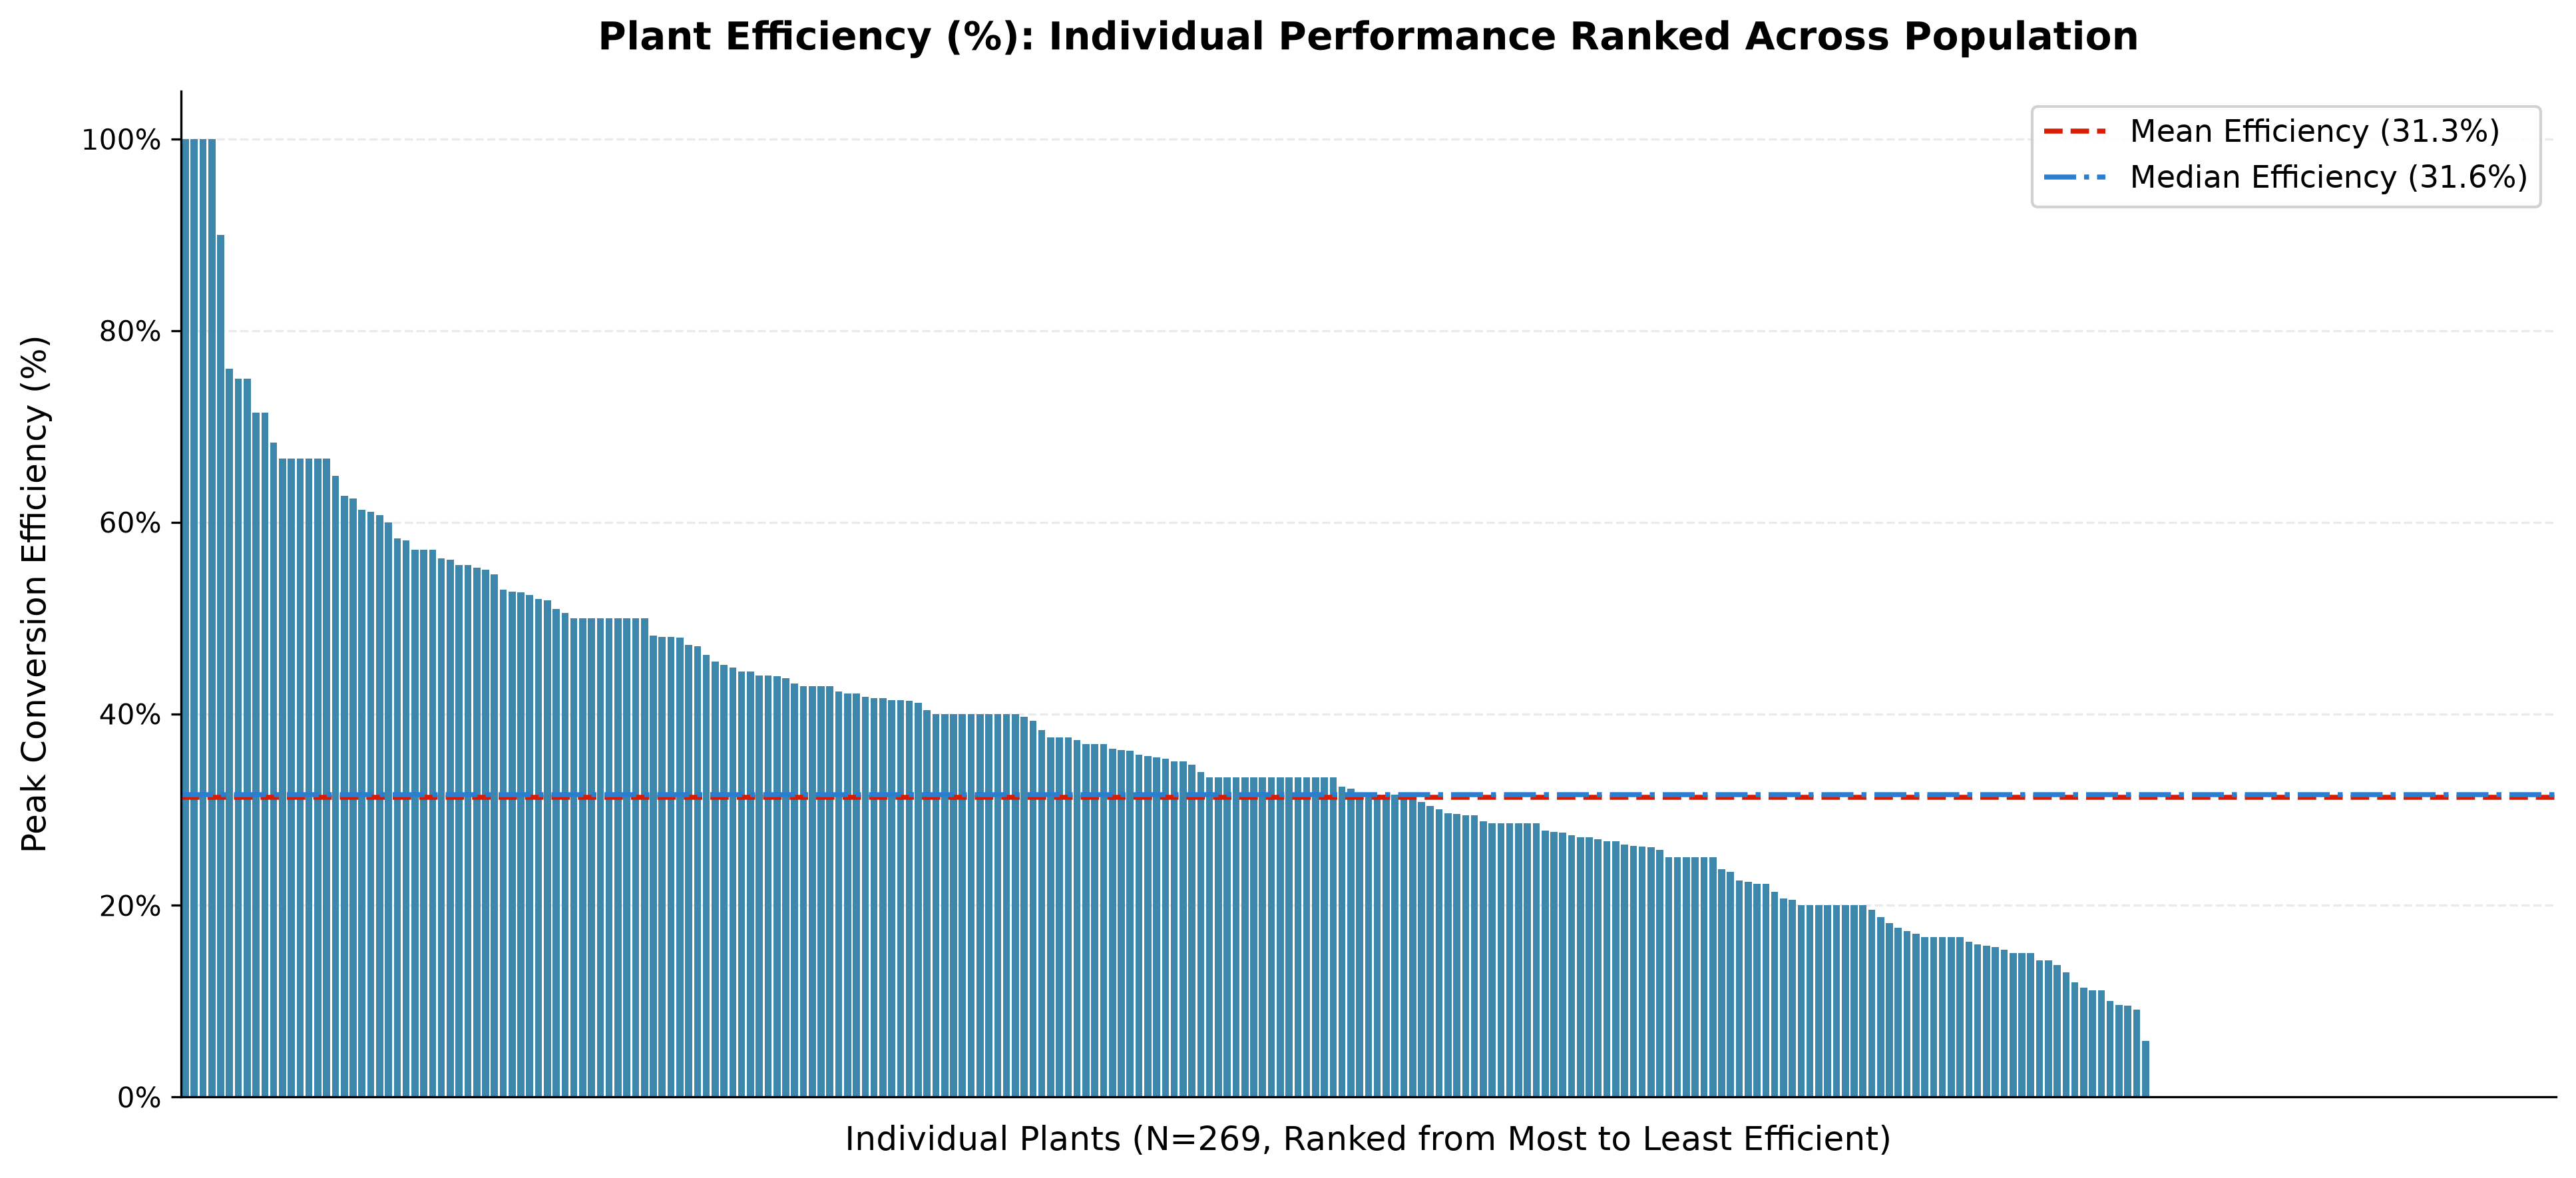

In [43]:
# Extract total flowers count and keep PlantID as a column
flower_total = (df.groupby("PlantID")["Estim.Flowers.Nr"].sum().reset_index())
# Extract max fruits count and keep PlantID as a column
seed_max = df.groupby("PlantID")["Estim.Fruits.Nr"].max().reset_index()
# Merge total flowers and max fruits together in a dataframe on PlantID
plant_max = pd.merge(flower_total, seed_max, on="PlantID")

# Calculate success percentage
plant_max["Success_Percentage"] = np.where(
    plant_max["Estim.Flowers.Nr"] > 0,
    (plant_max["Estim.Fruits.Nr"] / plant_max["Estim.Flowers.Nr"]) * 100,
    np.nan,  # Mark division-by-zero as NaN to remove cleanly
)

# Keep only valid plants with efficiency <= 100%
plant_max = plant_max[
    (plant_max["Success_Percentage"].notna())
    & (plant_max["Success_Percentage"] <= 100.0)
].copy()

# Sort from most to least efficient & reset integer row index for ranking
plant_max = plant_max.sort_values(by="Success_Percentage", ascending=False).reset_index(drop=True)

# PlantID is now preserved as a column:
print("Check plant_max structure with PlantID column:")
print(plant_max[["PlantID", "Estim.Flowers.Nr", "Estim.Fruits.Nr", "Success_Percentage"]].head())

# Plotting the ranked efficiency of individual plants
mean_pct = plant_max["Success_Percentage"].mean()
median_pct = plant_max["Success_Percentage"].median()
fig, ax = plt.subplots(figsize=(13, 6), dpi=300) # set figure size and resolution

sns.barplot(
    data=plant_max,
    x=plant_max.index,
    y="Success_Percentage",
    color="#2b8cbe",
    edgecolor="none",
    ax=ax,
)

# Mean & Median Lines
ax.axhline(
    mean_pct,
    color="#d91b02",
    linestyle="--",
    linewidth=1.8,
    label=f"Mean Efficiency ({mean_pct:.1f}%)",
)
ax.axhline(
    median_pct,
    color="#2b7dcf",
    linestyle="-.",
    linewidth=1.8,
    label=f"Median Efficiency ({median_pct:.1f}%)",
)

# Formatting
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(
    "Plant Efficiency (%): Individual Performance Ranked Across Population",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
ax.set_xlabel(
    f"Individual Plants (N={len(plant_max)}, Ranked from Most to Least Efficient)",
    fontsize=12,
    labelpad=10,
)
ax.set_ylabel("Peak Conversion Efficiency (%)", fontsize=12, labelpad=10)

ax.set_xticks([])
ax.grid(axis="y", linestyle="--", alpha=0.4, color="#cccccc")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(fontsize=11, loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

# Look at distribution of target variable

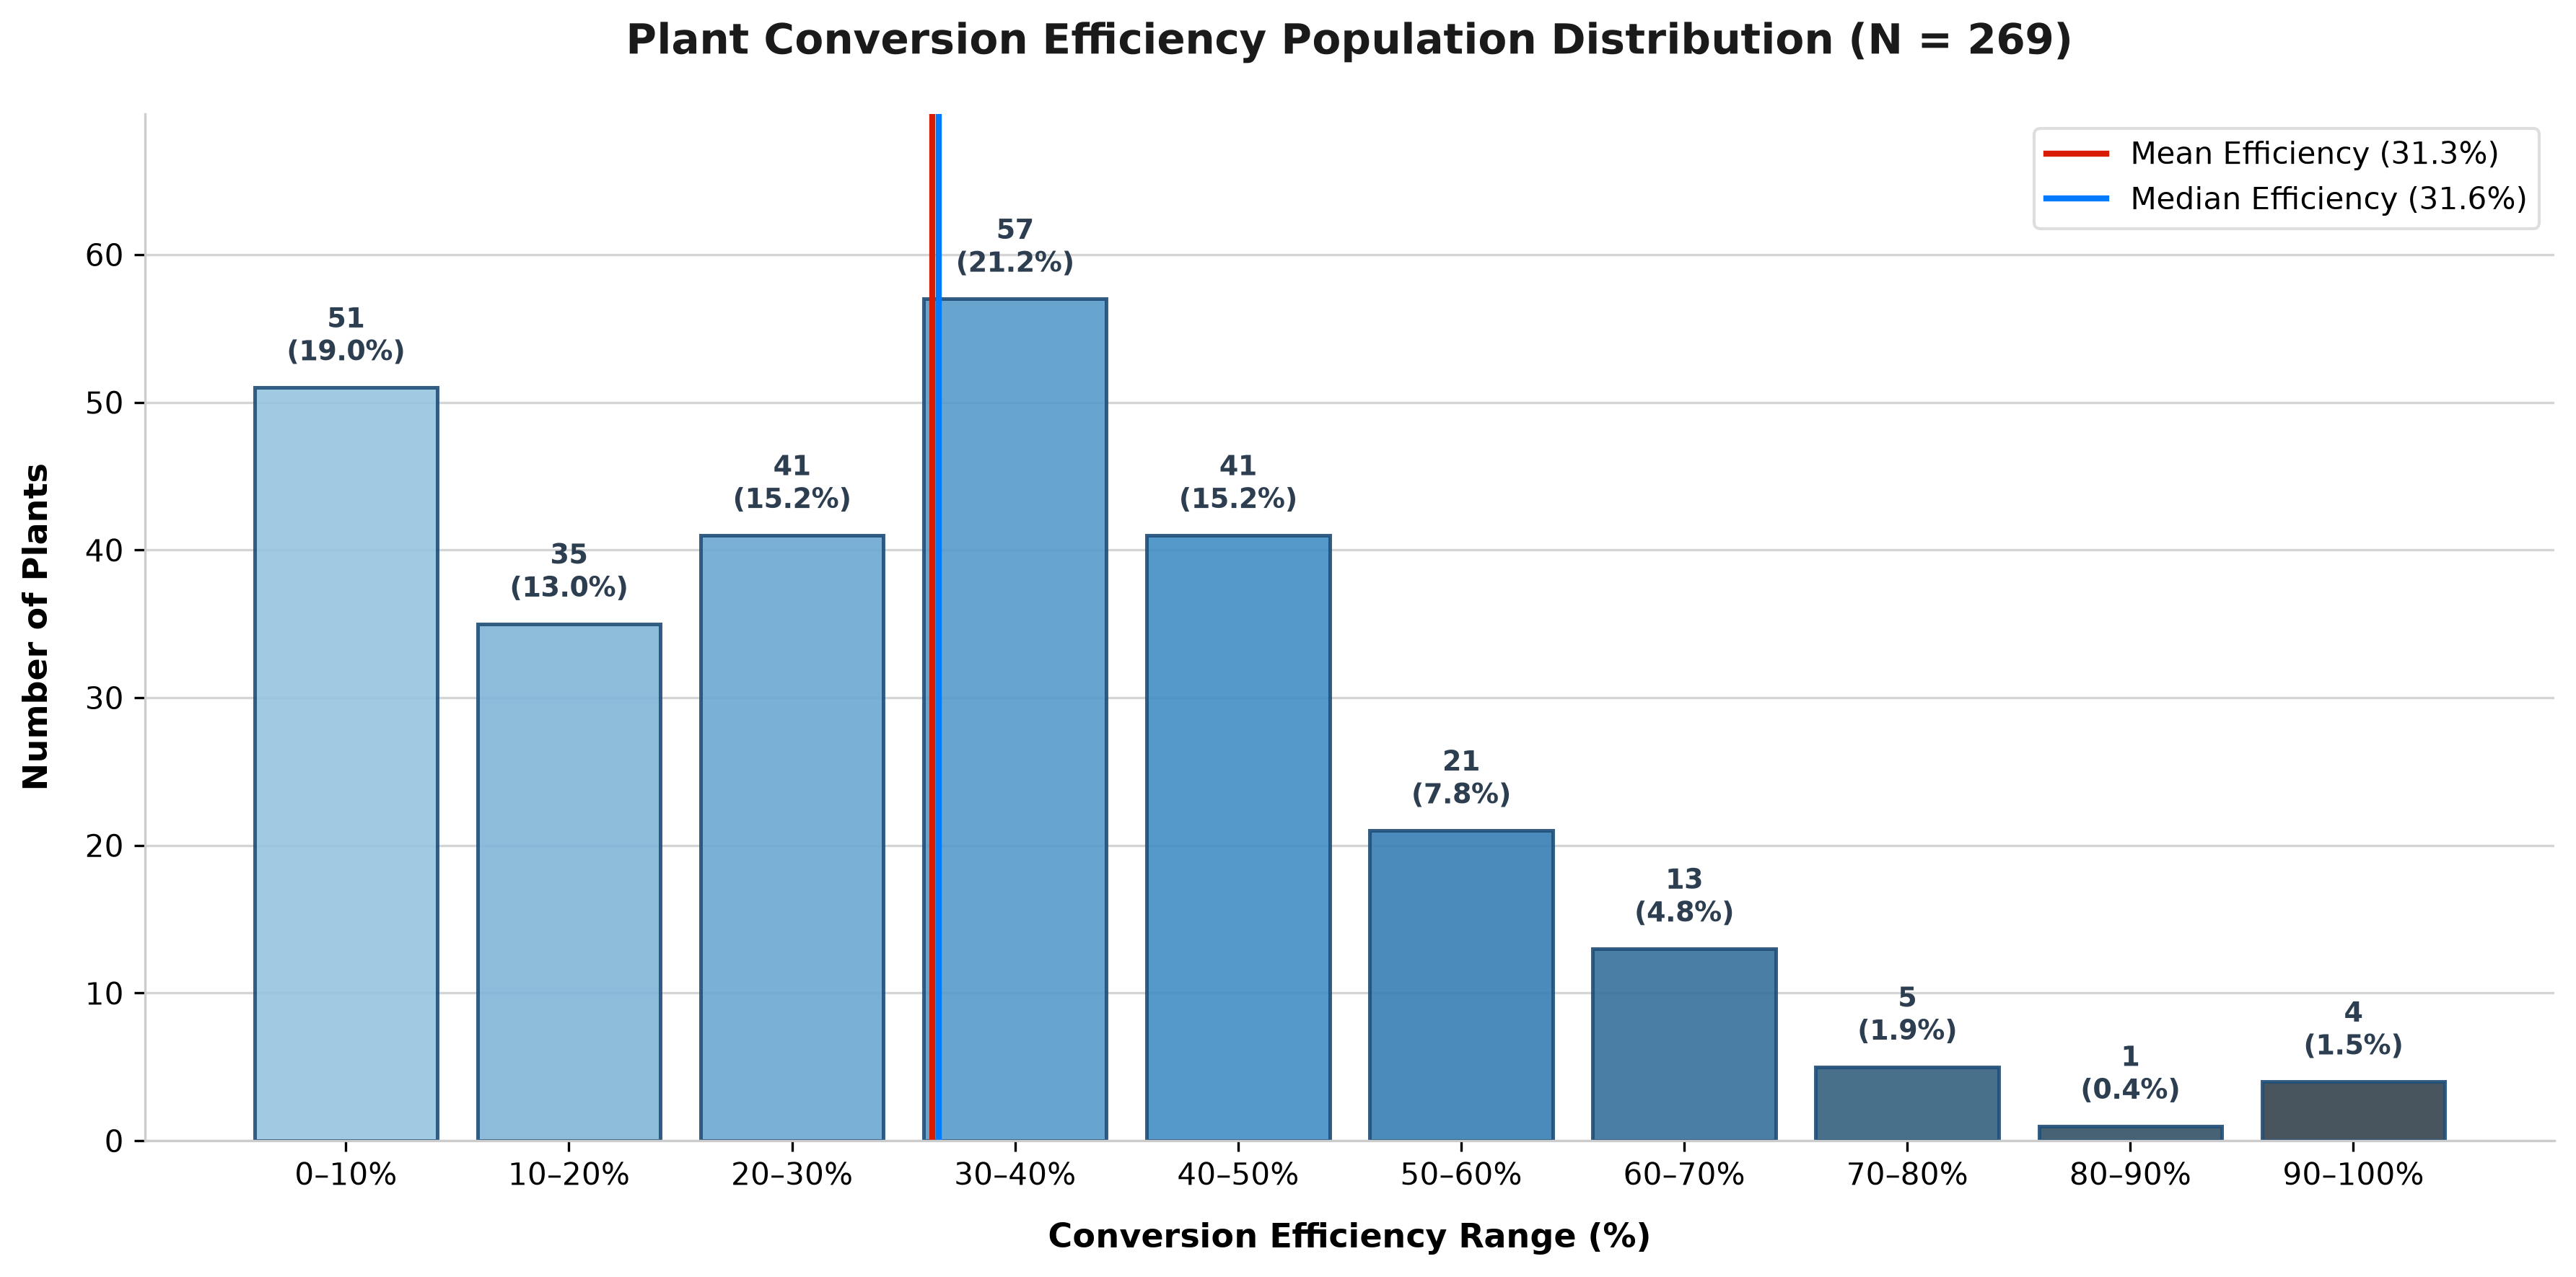

In [44]:
# Extract clean efficiency values
eff_series = plant_max["Success_Percentage"].dropna()

# 1. Define 10% Bins and Category Labels
bins = np.arange(0, 110, 10)  # [0, 10, 20, ..., 100]
bin_labels = [f"{i}–{i+10}%" for i in range(0, 100, 10)]

# 2. Categorize data and calculate counts + percentages
binned_df = (
    pd.cut(eff_series, bins=bins, labels=bin_labels, include_lowest=True, right=True)
    .value_counts()
    .sort_index()
    .reset_index()
)
binned_df.columns = ["Bin", "Count"]
binned_df["Percentage"] = (binned_df["Count"] / len(eff_series)) * 100

# Summary Stats
mean_val = eff_series.mean()
median_val = eff_series.median()

# ==========================================
# PLOTTING
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

# Smooth color gradient across bins
colors = sns.color_palette("Blues_d", n_colors=len(binned_df))

bars = ax.bar(
    binned_df["Bin"],
    binned_df["Count"],
    color=colors,
    edgecolor="#1f4e78",
    linewidth=1.2,
    width=0.82,
    alpha=0.9,
)

# Annotate counts and percentages on top of each bar
for bar, count, pct in zip(bars, binned_df["Count"], binned_df["Percentage"]):
    if count > 0:
        ax.annotate(
            f"{count}\n({pct:.1f}%)",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="#2c3e50",
        )

# Map continuous mean/median values to categorical x-positions
mean_x = (mean_val / 100) * len(bin_labels) - 0.5
median_x = (median_val / 100) * len(bin_labels) - 0.5

# Mean & Median Vertical Lines
ax.axvline(
    mean_x,
    color="#d91b02",
    linestyle="-",
    linewidth=2,
    label=f"Mean Efficiency ({mean_val:.1f}%)",
)
ax.axvline(
    median_x,
    color="#007aff",
    linestyle="-",
    linewidth=2,
    label=f"Median Efficiency ({median_val:.1f}%)",
)

# Axis & Label Formatting
ax.set_title(
    f"Plant Conversion Efficiency Population Distribution (N = {len(eff_series)})",
    fontsize=14,
    fontweight="bold",
    pad=20,
    color="#1a1a1a",
)
ax.set_xlabel(
    "Conversion Efficiency Range (%)", fontsize=11, fontweight="bold", labelpad=10
)
ax.set_ylabel("Number of Plants", fontsize=11, fontweight="bold", labelpad=10)

# Expand Y-axis so bar labels don't collide with the title
ax.set_ylim(0, binned_df["Count"].max() * 1.22)

# Grid & Spines Styling
ax.grid(axis="y", linestyle="-", alpha=0.35, color="#888888")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")

# Legend Placement
ax.legend(
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#dddddd",
    framealpha=0.95,
    fontsize=10,
)

plt.tight_layout()
plt.show()

## Data Extrapolating
Before continouing with modelling I extrapolate distance metrics for spatial features, like distance to rivers.     
I also added other features like elevation, slope degredation and if they face north or south. See below. 

In [45]:
# Calculate distance to nearest river node for each plant
# Detect ID column name in df_coordinates dynamically
id_col = "PlantID" if "PlantID" in df_coordinates.columns else "PlantIDs"

# Extract clean coordinates from df_coordinates
coords_clean = (
    df_coordinates.groupby(id_col)[["Latitude", "Longitude"]]
    .median()
    .reset_index()
    .rename(
        columns={
            id_col: "PlantID",
            "Latitude": "lat",
            "Longitude": "lng",
        }
    )
    .dropna(subset=["lat", "lng"])
)

# Extract trait metadata from df
traits_meta = (df.groupby("PlantID")[["Flower.colour", "Years_Alive_Count"]].first().reset_index())
# Merge clean coordinates and traits metadat
df_meta = pd.merge(coords_clean, traits_meta, on="PlantID", how="inner")
# Merge with target efficiency cohort (plant_max)
plants_df = pd.merge(
    plant_max[["PlantID", "Success_Percentage"]],
    df_meta,
    on="PlantID",
    how="inner",
)
print(f"Plants retained with clean coordinates: {len(plants_df)} / {len(plant_max)}")

# Project to UTM Zone 31N (EPSG:32631) for accurate distance calculations
plants_gdf = gpd.GeoDataFrame(
    plants_df,
    geometry=gpd.points_from_xy(plants_df.lng, plants_df.lat),
    crs="EPSG:4326",
).to_crs(epsg=32631)
bounds = plants_gdf.to_crs(epsg=4326).total_bounds
buffer_deg = 0.02
min_x, min_y = bounds[0] - buffer_deg, bounds[1] - buffer_deg
max_x, max_y = bounds[2] + buffer_deg, bounds[3] + buffer_deg

# upload river vector data and extract river nodes
river_gpkg_path = "../data/raw/IGR_HI_v1_ES100_Cuencas_Internas_Cataluna.gpkg"
river_points = []
with fiona.open(river_gpkg_path, layer="hi_rednodo_p_es100") as src:
    crs = src.crs
    for feat in src:
        coords = feat["geometry"]["coordinates"]
        river_points.append(Point(coords[0], coords[1]))
river_nodes = gpd.GeoDataFrame(geometry=river_points, crs=crs)
river_local = river_nodes.to_crs(epsg=4326).cx[min_x:max_x, min_y:max_y]
river_nodes_utm = river_local.to_crs(epsg=32631)
plants_gdf["dist_to_river_m"] = plants_gdf.geometry.apply(lambda p: river_nodes_utm.distance(p).min())
coordinates_df = plants_gdf
print(plants_gdf.head())

Plants retained with clean coordinates: 269 / 269
  PlantID  Success_Percentage        lat       lng Flower.colour  \
0  PF0785               100.0  42.322270  2.072778     No flower   
1  PF0667               100.0  42.323687  2.080236       Magenta   
2  PF0693               100.0  42.323604  2.078830       Magenta   
3  PF0652               100.0  42.322724  2.074251        Hybrid   
4  PF0666                90.0  42.323694  2.079669       Magenta   

   Years_Alive_Count                        geometry  dist_to_river_m  
0                  0    POINT (423598.008 4685974.8)        90.785869  
1                  1  POINT (424214.299 4686125.468)        78.601437  
2                  0  POINT (424098.356 4686117.451)        52.062495  
3                  1  POINT (423719.973 4686023.866)        51.767727  
4                  1  POINT (424167.578 4686126.694)        42.728400  


In [46]:
# Calculate elevation for each plant using the downloaded DEM data. 
# The DEM file is a GeoTIFF that contains elevation data for the region of interest. 
# The code below reads the DEM, checks its coordinate reference system (CRS), and extracts the elevation values at each plant's coordinates.
dem_path = "../data/raw/FME_46302427_1792336098447_24232/elevacions-terreny-lidar-Catalunya-50cm-2021-2023tif1792336098367.tif"

# Automatically check the DEM's CRS and align the plant coordinates
with rasterio.open(dem_path) as src:
    dem_crs = src.crs.to_epsg()
    print(f"DEM CRS: EPSG:{dem_crs}")

plants_gdf = plants_gdf.to_crs(epsg=dem_crs)

# Extract elevation values at each plant coordinate
elevations = []
with rasterio.open(dem_path) as src:
    for idx, row in plants_gdf.iterrows():
        coord = [(row.geometry.x, row.geometry.y)]
        try:
            # Sample the raster at the specific X, Y coordinate
            val = next(src.sample(coord))[0]
            elevations.append(val)
        except IndexError:
            # Handles edge cases if a point falls exactly outside the downloaded DEM box
            elevations.append(None)

# Save to the dataframe
plants_gdf["elevation_m"] = elevations
# Inspect the results to ensure it worked
print(plants_gdf[["elevation_m"]].head())

DEM CRS: EPSG:25831
   elevation_m
0  1155.040039
1  1132.946045
2  1134.312988
3  1144.452026
4  1133.069946


In [47]:
# calculate slope and northness for each plant using the DEM
slopes = []
northness_list = []

with rasterio.open(dem_path) as src:
    res_x, res_y = src.res  # Resolution (e.g., 0.5m x 0.5m)
    
    for idx, row in plants_gdf.iterrows():
        # Get raster row/col index
        r, c = src.index(row.geometry.x, row.geometry.y)
        
        # Read 3x3 pixel window
        window = rasterio.windows.Window(c - 1, r - 1, 3, 3)
        elev_window = src.read(1, window=window)
        
        if elev_window.shape == (3, 3) and not np.isnan(elev_window).any():
            # Gradients (Sobel filter)
            dz_dx = ((elev_window[0, 2] + 2*elev_window[1, 2] + elev_window[2, 2]) - 
                     (elev_window[0, 0] + 2*elev_window[1, 0] + elev_window[2, 0])) / (8 * res_x)
            dz_dy = ((elev_window[2, 0] + 2*elev_window[2, 1] + elev_window[2, 2]) - 
                     (elev_window[0, 0] + 2*elev_window[0, 1] + elev_window[0, 2])) / (8 * res_y)
            
            # Slope in degrees
            slope_deg = np.degrees(np.arctan(np.sqrt(dz_dx**2 + dz_dy**2)))
            
            # Aspect & Northness: cos(Aspect in radians)
            aspect_deg = np.degrees(np.arctan2(-dz_dy, dz_dx))
            if aspect_deg < 0:
                aspect_deg += 360
            northness = np.cos(np.radians(aspect_deg))
            
            slopes.append(slope_deg)
            northness_list.append(northness)
        else:
            slopes.append(np.nan)
            northness_list.append(np.nan)

# Save directly into plants_gdf
plants_gdf["slope_deg"] = slopes
plants_gdf["northness"] = northness_list

# Verify all environmental predictors in one dataframe
cols_to_show = [c for c in ["slope_deg", "northness"] if c in plants_gdf.columns]
print(plants_gdf[cols_to_show])

     slope_deg  northness
0    47.657982  -0.419594
1    14.708846  -0.223671
2    14.961905  -0.142061
3     5.205042  -0.353765
4     4.008804   0.019160
..         ...        ...
264   4.744531   0.075009
265  34.195526  -0.499251
266  24.436026   0.182147
267  58.615471  -0.531022
268   1.116860  -0.882872

[269 rows x 2 columns]


In [48]:
# calculate terrain ruggedness index (TRI) for each plant using the DEM data. 
# TRI is a measure of the variability in elevation within a specified area, which can influence microhabitat conditions for plants.
tri_list = []

with rasterio.open(dem_path) as src:
    for idx, row in plants_gdf.iterrows():
        r, c = src.index(row.geometry.x, row.geometry.y)
        
        # Read 3x3 pixel neighborhood around plant
        window = rasterio.windows.Window(c - 1, r - 1, 3, 3)
        elev_window = src.read(1, window=window)
        
        if elev_window.shape == (3, 3) and not np.isnan(elev_window).any():
            center_val = elev_window[1, 1]
            # Exclude center pixel to get the 8 surrounding neighbors
            neighbors = np.delete(elev_window.flatten(), 4)
            
            # Root mean square of elevation differences
            tri = np.sqrt(np.mean((neighbors - center_val) ** 2))
            tri_list.append(tri)
        else:
            tri_list.append(np.nan)

plants_gdf["tri_ruggedness"] = tri_list
print(plants_gdf[["tri_ruggedness"]].head())

   tri_ruggedness
0        0.471634
1        0.189201
2        0.112029
3        0.042082
4        0.030918


In [49]:
# calculate NDVI values for each plant using the downloaded NDVI TIF data.
# NDVI (Normalized Difference Vegetation Index) is a measure of vegetation health and density, derived from satellite imagery. 
# The code below reads the NDVI GeoTIFF file, checks its coordinate reference system (CRS), and extracts the NDVI values at each plant's coordinates.
ndvi_tif_path = "../data/raw/Browser_images/2026-07-05-00_00_2026-07-05-23_59_Sentinel-2_L2A_NDVI.tiff"  # Update with your filename

with rasterio.open(ndvi_tif_path) as src:
    data = src.read(1)
    print("Raster shape (pixels):", data.shape)
    print("Data type:", src.dtypes[0]) 
    print("Min NDVI value:", np.nanmin(data))
    print("Max NDVI value:", np.nanmax(data))

    # calculate NDVI values for each plant using the downloaded NDVI TIF
ndvi_values = []

with rasterio.open(ndvi_tif_path) as src:
    # Automatically reproject plants to match raster coordinate system
    plants_in_raster_crs = plants_gdf.to_crs(src.crs)
    
    for idx, row in plants_in_raster_crs.iterrows():
        coord = [(row.geometry.x, row.geometry.y)]
        try:
            val = next(src.sample(coord))[0]
            if -1.0 <= val <= 1.0:
                ndvi_values.append(float(val))
            else:
                ndvi_values.append(np.nan)
        except IndexError:
            ndvi_values.append(np.nan)

# 2. Assign values into the master GeoDataFrame
plants_gdf["ndvi"] = ndvi_values

# 3. View the completed environmental matrix
cols_to_view = [
    col for col in ["ndvi"] 
    if col in plants_gdf.columns
]
print(plants_gdf[cols_to_view].head())

Raster shape (pixels): (48, 128)
Data type: float32
Min NDVI value: 0.043137256
Max NDVI value: 0.5058824
       ndvi
0  0.164706
1  0.141176
2  0.396078
3  0.180392
4  0.231373


In [50]:
# look at the first few rows of the final GeoDataFrame to ensure all environmental predictors are included
print(plants_gdf.head())

  PlantID  Success_Percentage        lat       lng Flower.colour  \
0  PF0785               100.0  42.322270  2.072778     No flower   
1  PF0667               100.0  42.323687  2.080236       Magenta   
2  PF0693               100.0  42.323604  2.078830       Magenta   
3  PF0652               100.0  42.322724  2.074251        Hybrid   
4  PF0666                90.0  42.323694  2.079669       Magenta   

   Years_Alive_Count                        geometry  dist_to_river_m  \
0                  0    POINT (423598.008 4685974.8)        90.785869   
1                  1  POINT (424214.299 4686125.468)        78.601437   
2                  0  POINT (424098.356 4686117.451)        52.062495   
3                  1  POINT (423719.973 4686023.866)        51.767727   
4                  1  POINT (424167.578 4686126.694)        42.728400   

   elevation_m  slope_deg  northness  tri_ruggedness      ndvi  
0  1155.040039  47.657982  -0.419594        0.471634  0.164706  
1  1132.946045  14.708

## Data Diagnotics
In order to decide a model choice looked at feature relationships. 

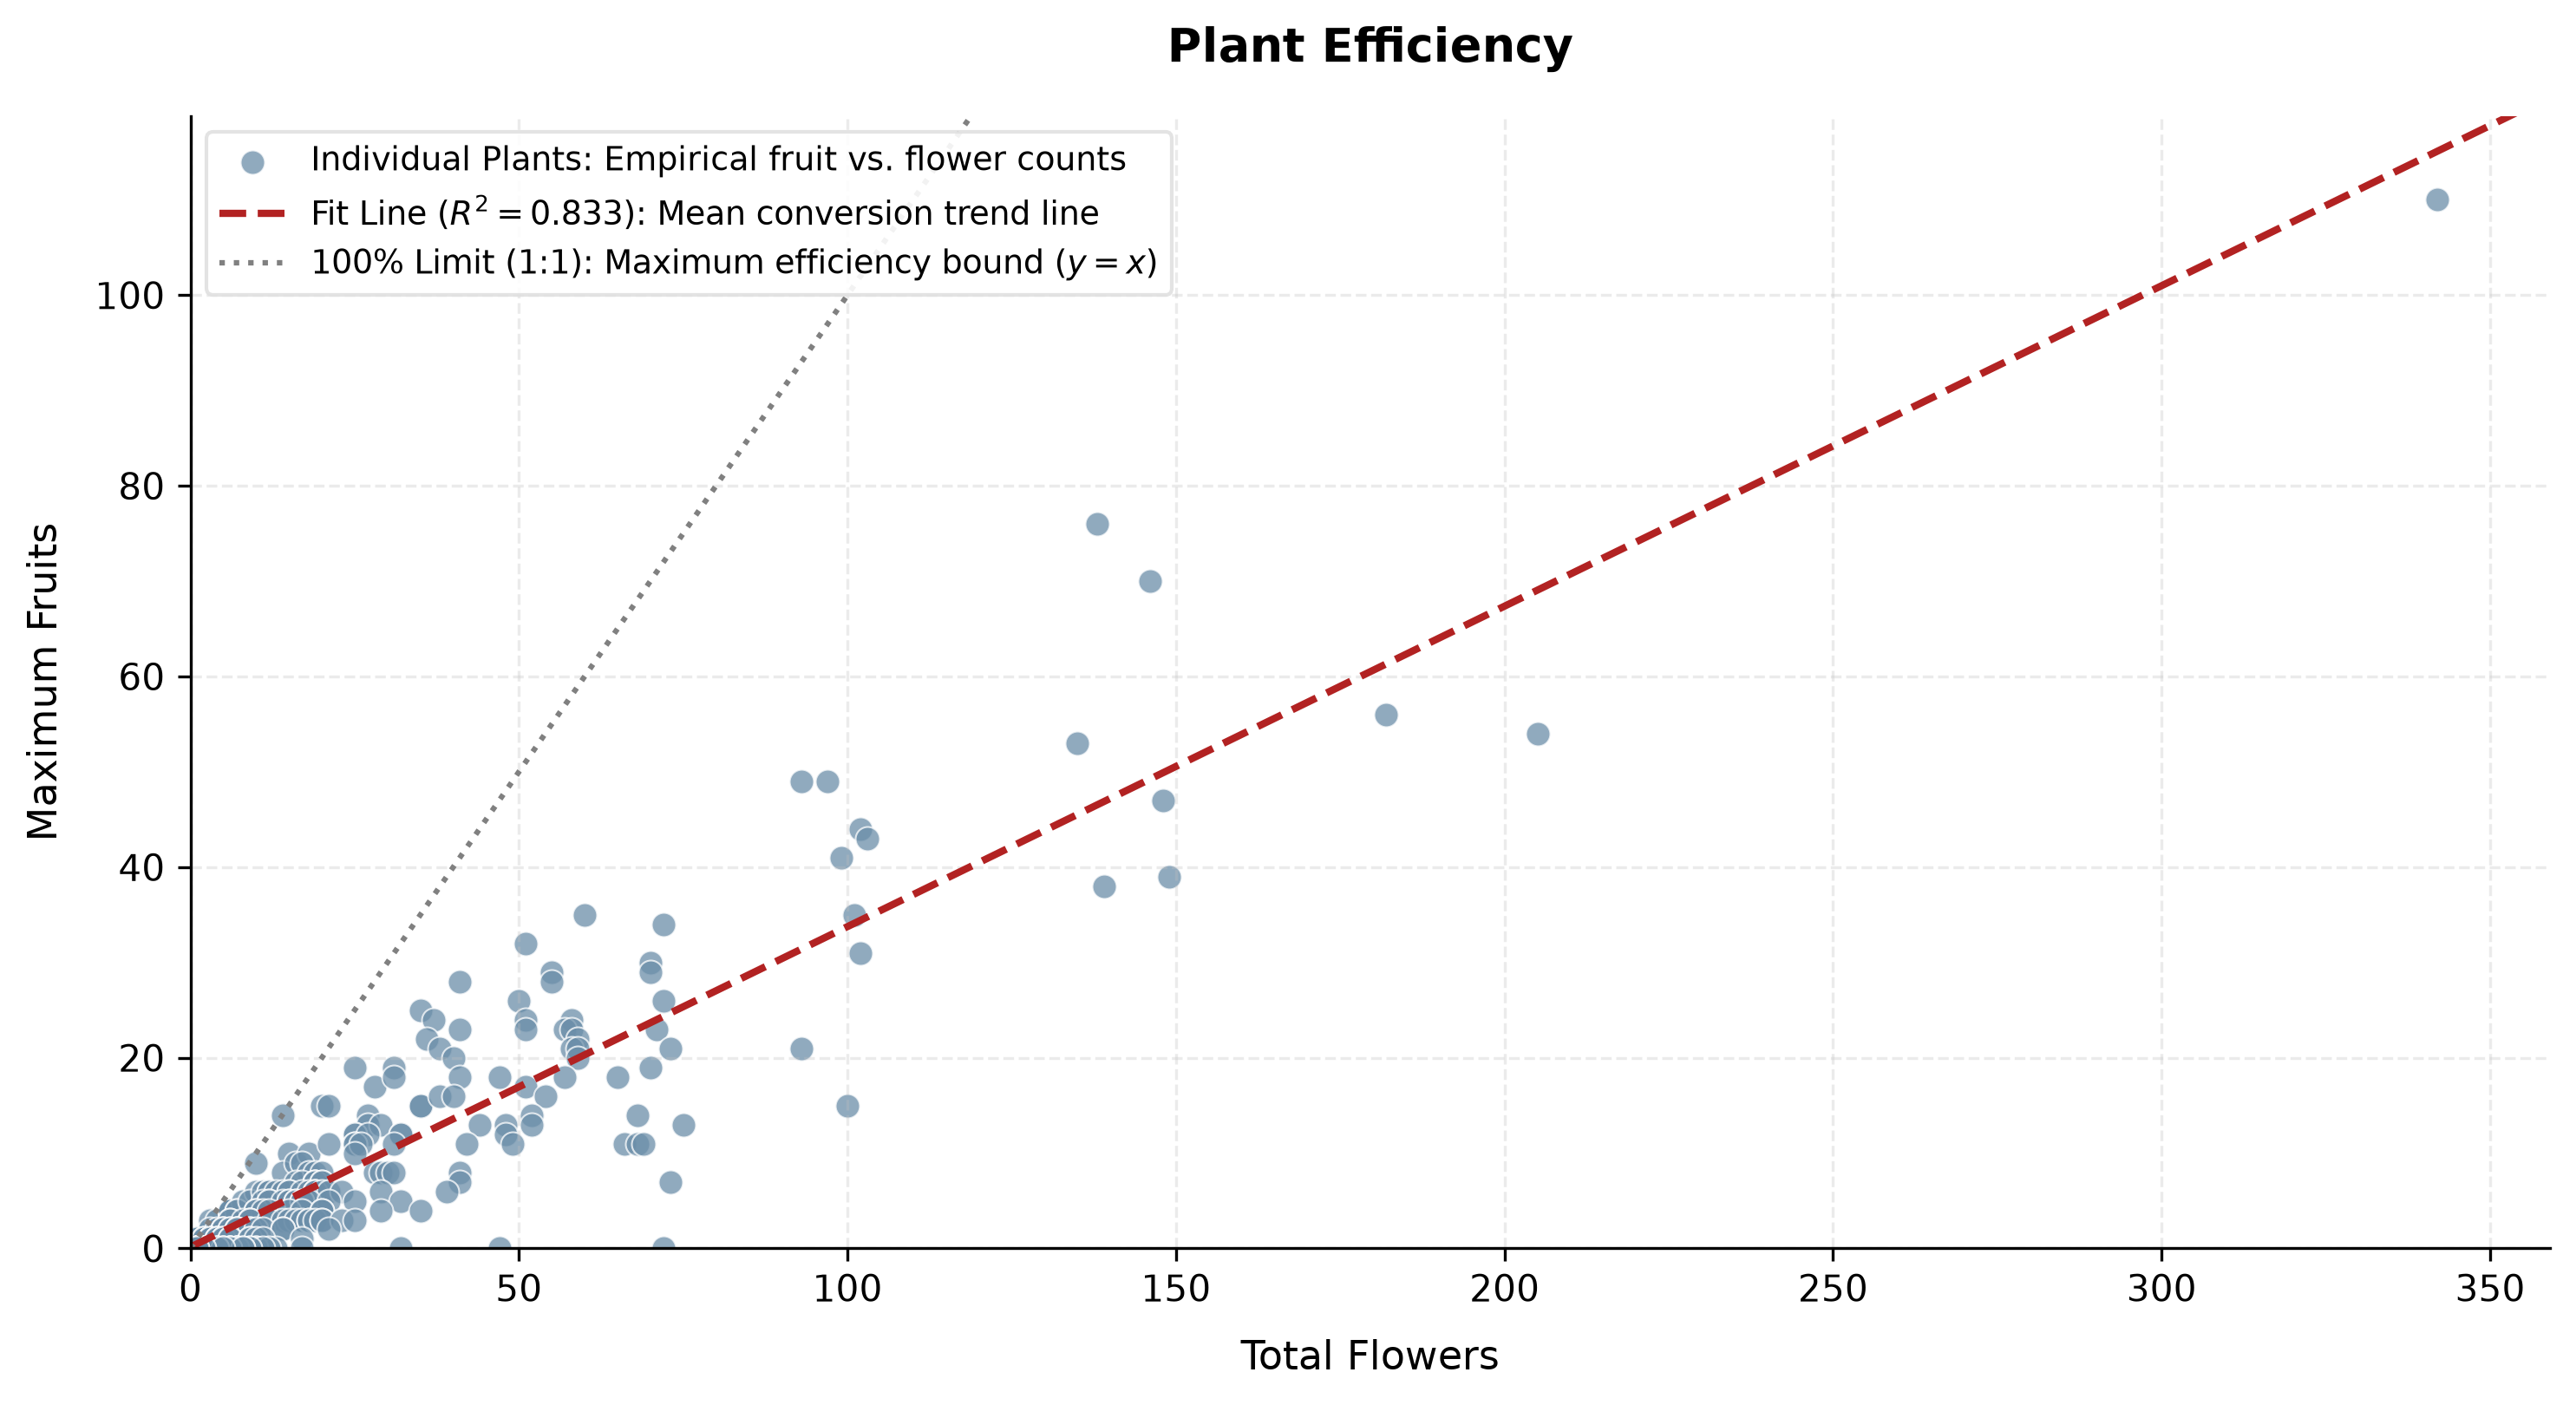

In [51]:
# linear regression analysis to assess the relationship between flower counts and fruit counts
flower_col = "Estim.Flowers.Nr"
fruit_col = "Estim.Fruits.Nr"

# Calculate linear regression slope, intercept, and R-squared
slope, intercept, r_value, p_value, std_err = linregress(plant_max[flower_col], plant_max[fruit_col])
r2 = r_value ** 2

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

# individual plant scatter points
sns.scatterplot(
    data=plant_max,
    x=flower_col,
    y=fruit_col,
    color='#6B8EA9',
    alpha=0.75,
    edgecolor='white',
    linewidth=0.5,
    s=45,
    ax=ax,
    label='Individual Plants: Empirical fruit vs. flower counts'
)
max_x = plant_max[flower_col].max() * 1.05
max_y = plant_max[fruit_col].max() * 1.08
x_line = np.linspace(0, max_x, 200)
# fit line based on linear regression
y_fit = slope * x_line + intercept
ax.plot(
    x_line, y_fit, 
    color='#B22222', linestyle='--', linewidth=2, 
    label=f'Fit Line ($R^2 = {r2:.3f}$): Mean conversion trend line'
)
# 100% Limit Line (1:1)
ax.plot(
    x_line, x_line, 
    color='#808080', linestyle=':', linewidth=1.5, 
    label='100% Limit (1:1): Maximum efficiency bound ($y = x$)'
)
ax.set_title("Plant Efficiency", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Total Flowers", fontsize=11, labelpad=8)
ax.set_ylabel("Maximum Fruits", fontsize=11, labelpad=8)
ax.set_xlim(0, max_x)
ax.set_ylim(0, max_y)
sns.despine(ax=ax)
# Grid and Legend with detailed line descriptions
ax.grid(True, linestyle='--', alpha=0.3, color='#C0C0C0')
ax.legend(
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='#E0E0E0', 
    framealpha=0.9, 
    fontsize=9
)
plt.tight_layout()
plt.style.use('default')
plt.show()

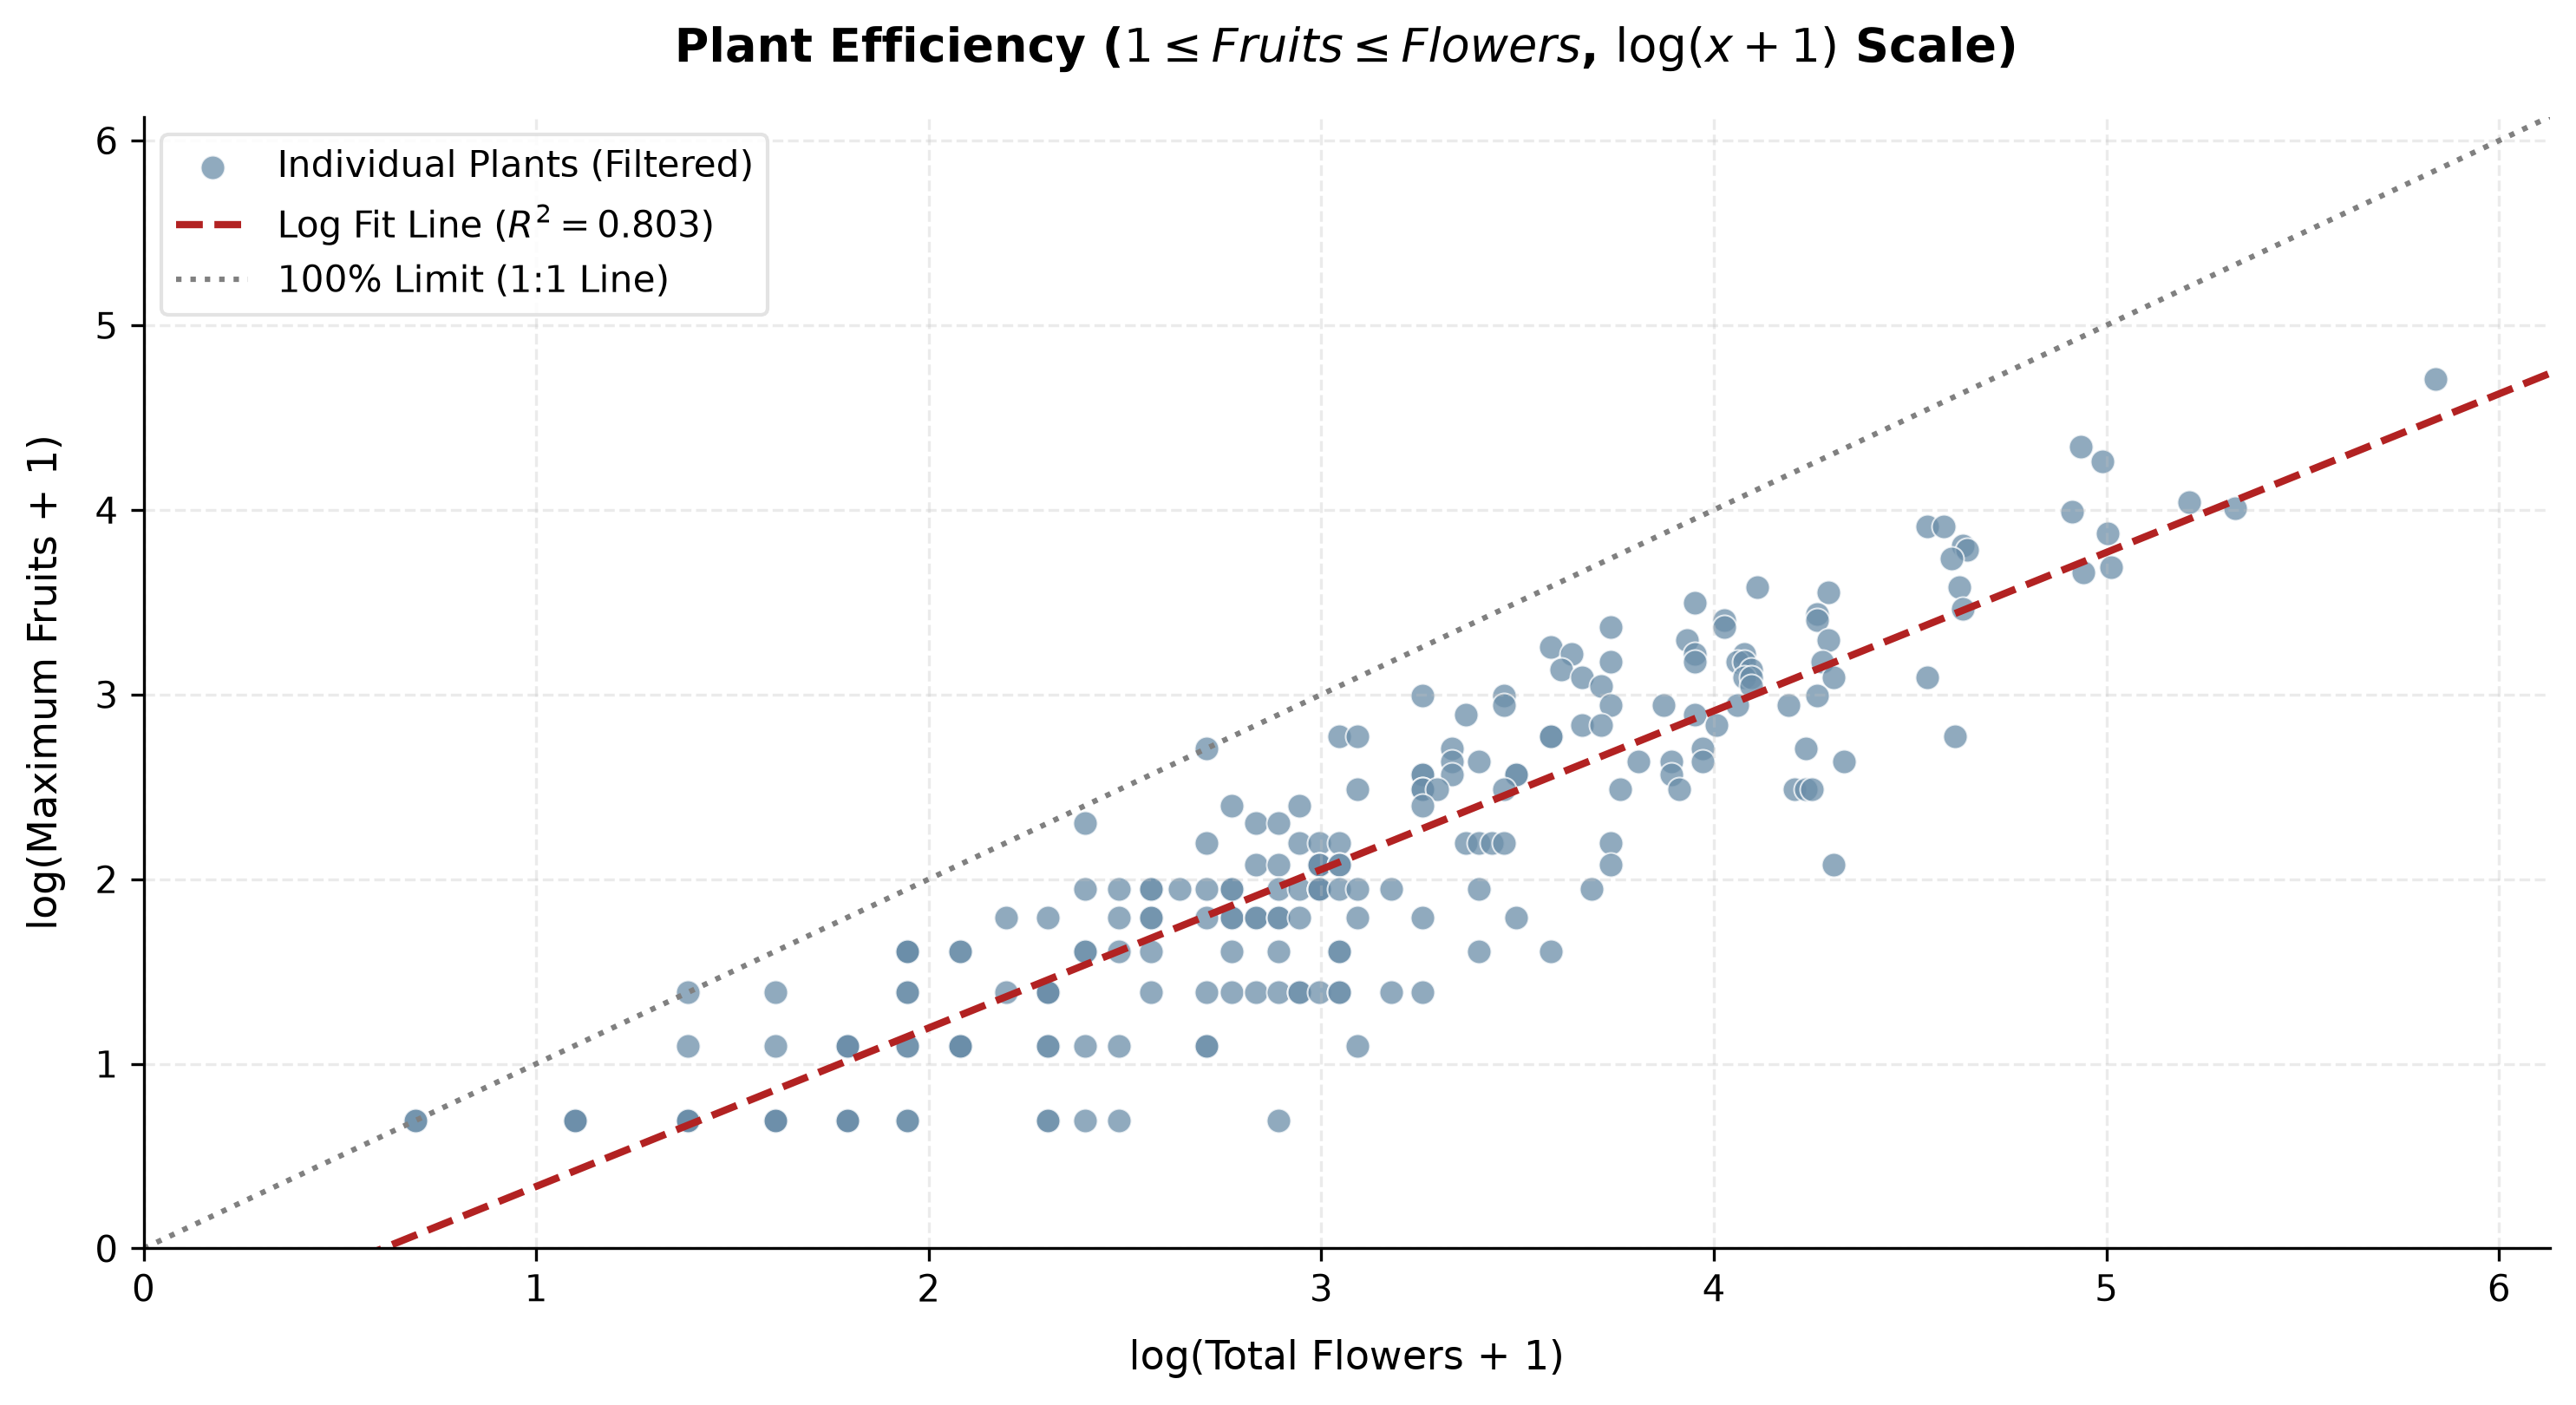

In [52]:
# make the log-log plot to visualize the relationship between flower counts and fruit counts.
flower_col = "Estim.Flowers.Nr"
fruit_col = "Estim.Fruits.Nr"

# 1. Filter Data (1 <= Fruits <= Flowers)
df_filtered = plant_max[
    (plant_max[fruit_col] >= 1) & 
    (plant_max[fruit_col] <= plant_max[flower_col])
].copy()

# 2. Log1p Transformation
log_flowers = np.log1p(df_filtered[flower_col])
log_fruits = np.log1p(df_filtered[fruit_col])

# Calculate linear regression on log-transformed data
slope, intercept, r_value, p_value, std_err = linregress(log_flowers, log_fruits)
r2 = r_value ** 2

# 3. Plotting
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

# Scatter plot of log-transformed individual plants
sns.scatterplot(
    x=log_flowers,
    y=log_fruits,
    color='#6B8EA9',
    alpha=0.75,
    edgecolor='white',
    linewidth=0.5,
    s=45,
    ax=ax,
    label='Individual Plants (Filtered)'
)

# Reference line domain
max_val = max(log_flowers.max(), log_fruits.max()) * 1.05
x_line = np.linspace(0, max_val, 200)

# Log fit line
y_fit = slope * x_line + intercept
ax.plot(
    x_line, y_fit, 
    color='#B22222', linestyle='--', linewidth=2, 
    label=f'Log Fit Line ($R^2 = {r2:.3f}$)'
)

# 100% Limit line (1:1 Reference in log-space)
ax.plot(
    x_line, x_line, 
    color='#808080', linestyle=':', linewidth=1.5, 
    label='100% Limit (1:1 Line)'
)

# Formatting
ax.set_title(r"Plant Efficiency ($1 \leq Fruits \leq Flowers$, $\log(x+1)$ Scale)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("log(Total Flowers + 1)", fontsize=11, labelpad=8)
ax.set_ylabel("log(Maximum Fruits + 1)", fontsize=11, labelpad=8)

ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
sns.despine(ax=ax)

ax.grid(True, linestyle='--', alpha=0.3, color='#C0C0C0')
ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#E0E0E0', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.style.use('default')
plt.show()

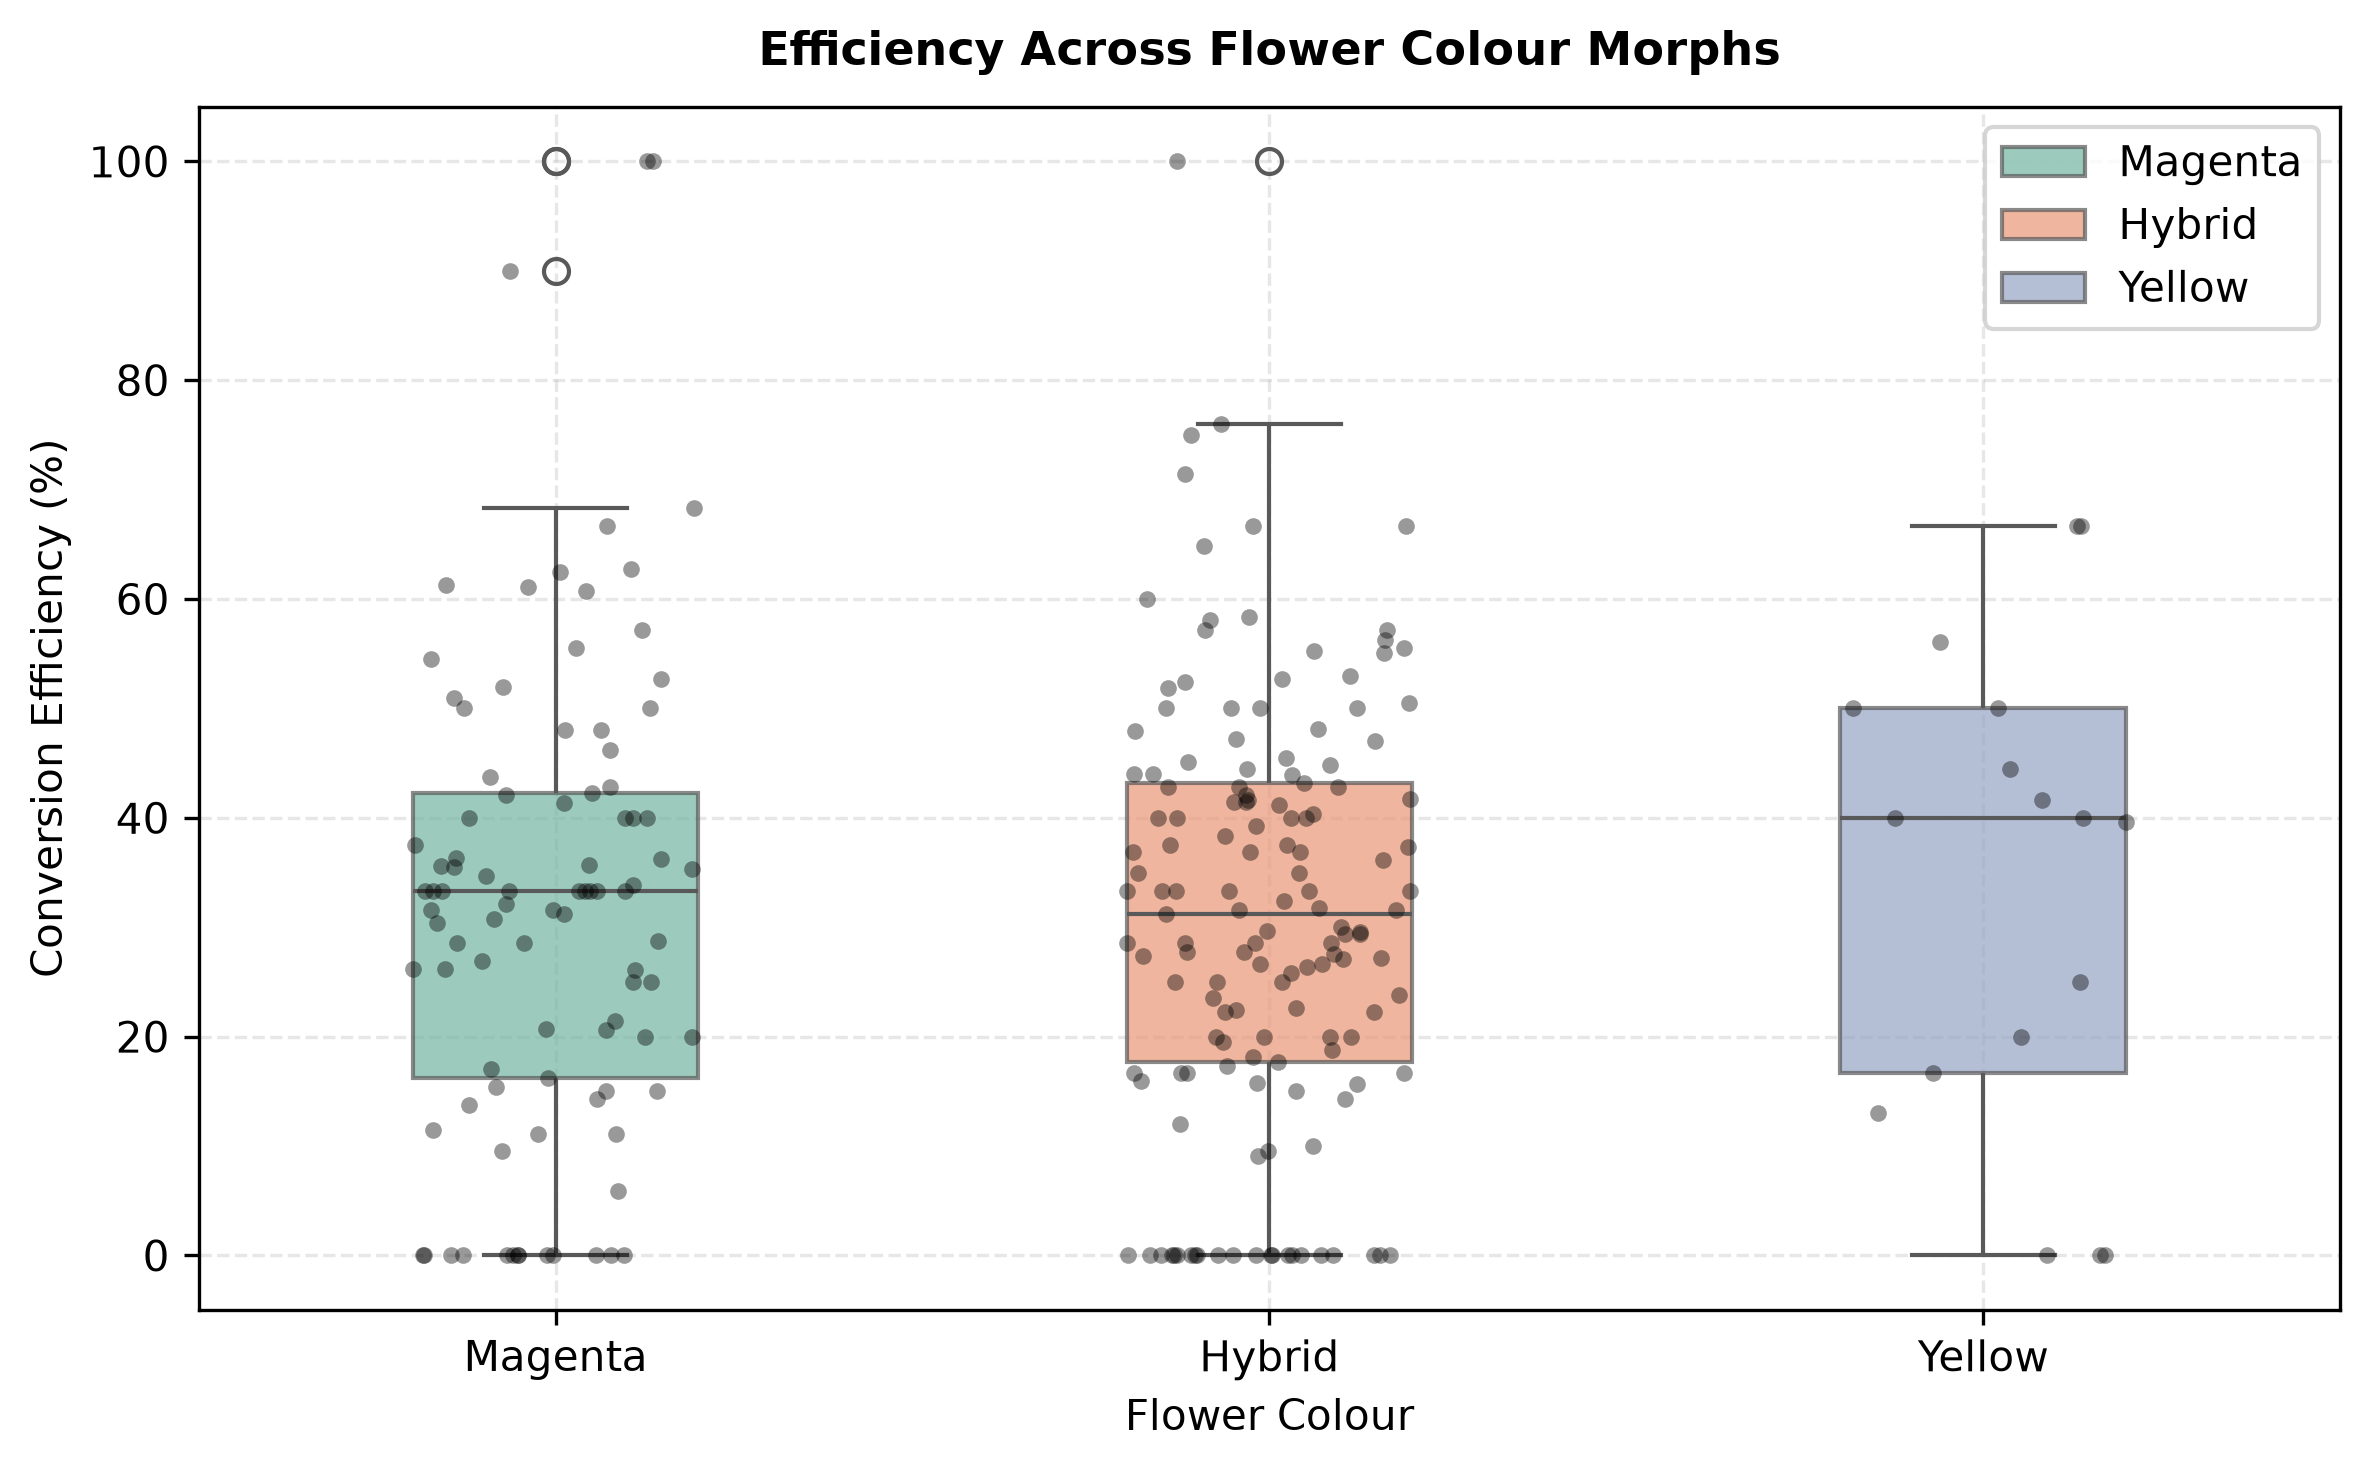

In [53]:
# I also look at the relationship between flower colour and conversion efficiency. 
# I use a boxplot to visualize the distribution of conversion efficiency across different flower colour morphs.
exp_data = plants_gdf[plants_gdf['Flower.colour'] != 'No flower'].copy()
fig, ax1 = plt.subplots(figsize=(8, 5), dpi=300)
sns.boxplot(
    data=exp_data,
    x='Flower.colour',
    y='Success_Percentage',
    hue='Flower.colour',
    palette='Set2',
    ax=ax1,
    width=0.4,
    boxprops=dict(alpha=0.7)
)
sns.stripplot(
    data=exp_data,
    x='Flower.colour',
    y='Success_Percentage',
    color='black',
    alpha=0.4,
    jitter=0.2,
    size=4,
    ax=ax1
)
ax1.set_title("Efficiency Across Flower Colour Morphs", fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel("Flower Colour", fontsize=10)
ax1.set_ylabel("Conversion Efficiency (%)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.3)
plt.style.use('default')
plt.tight_layout()
plt.show()

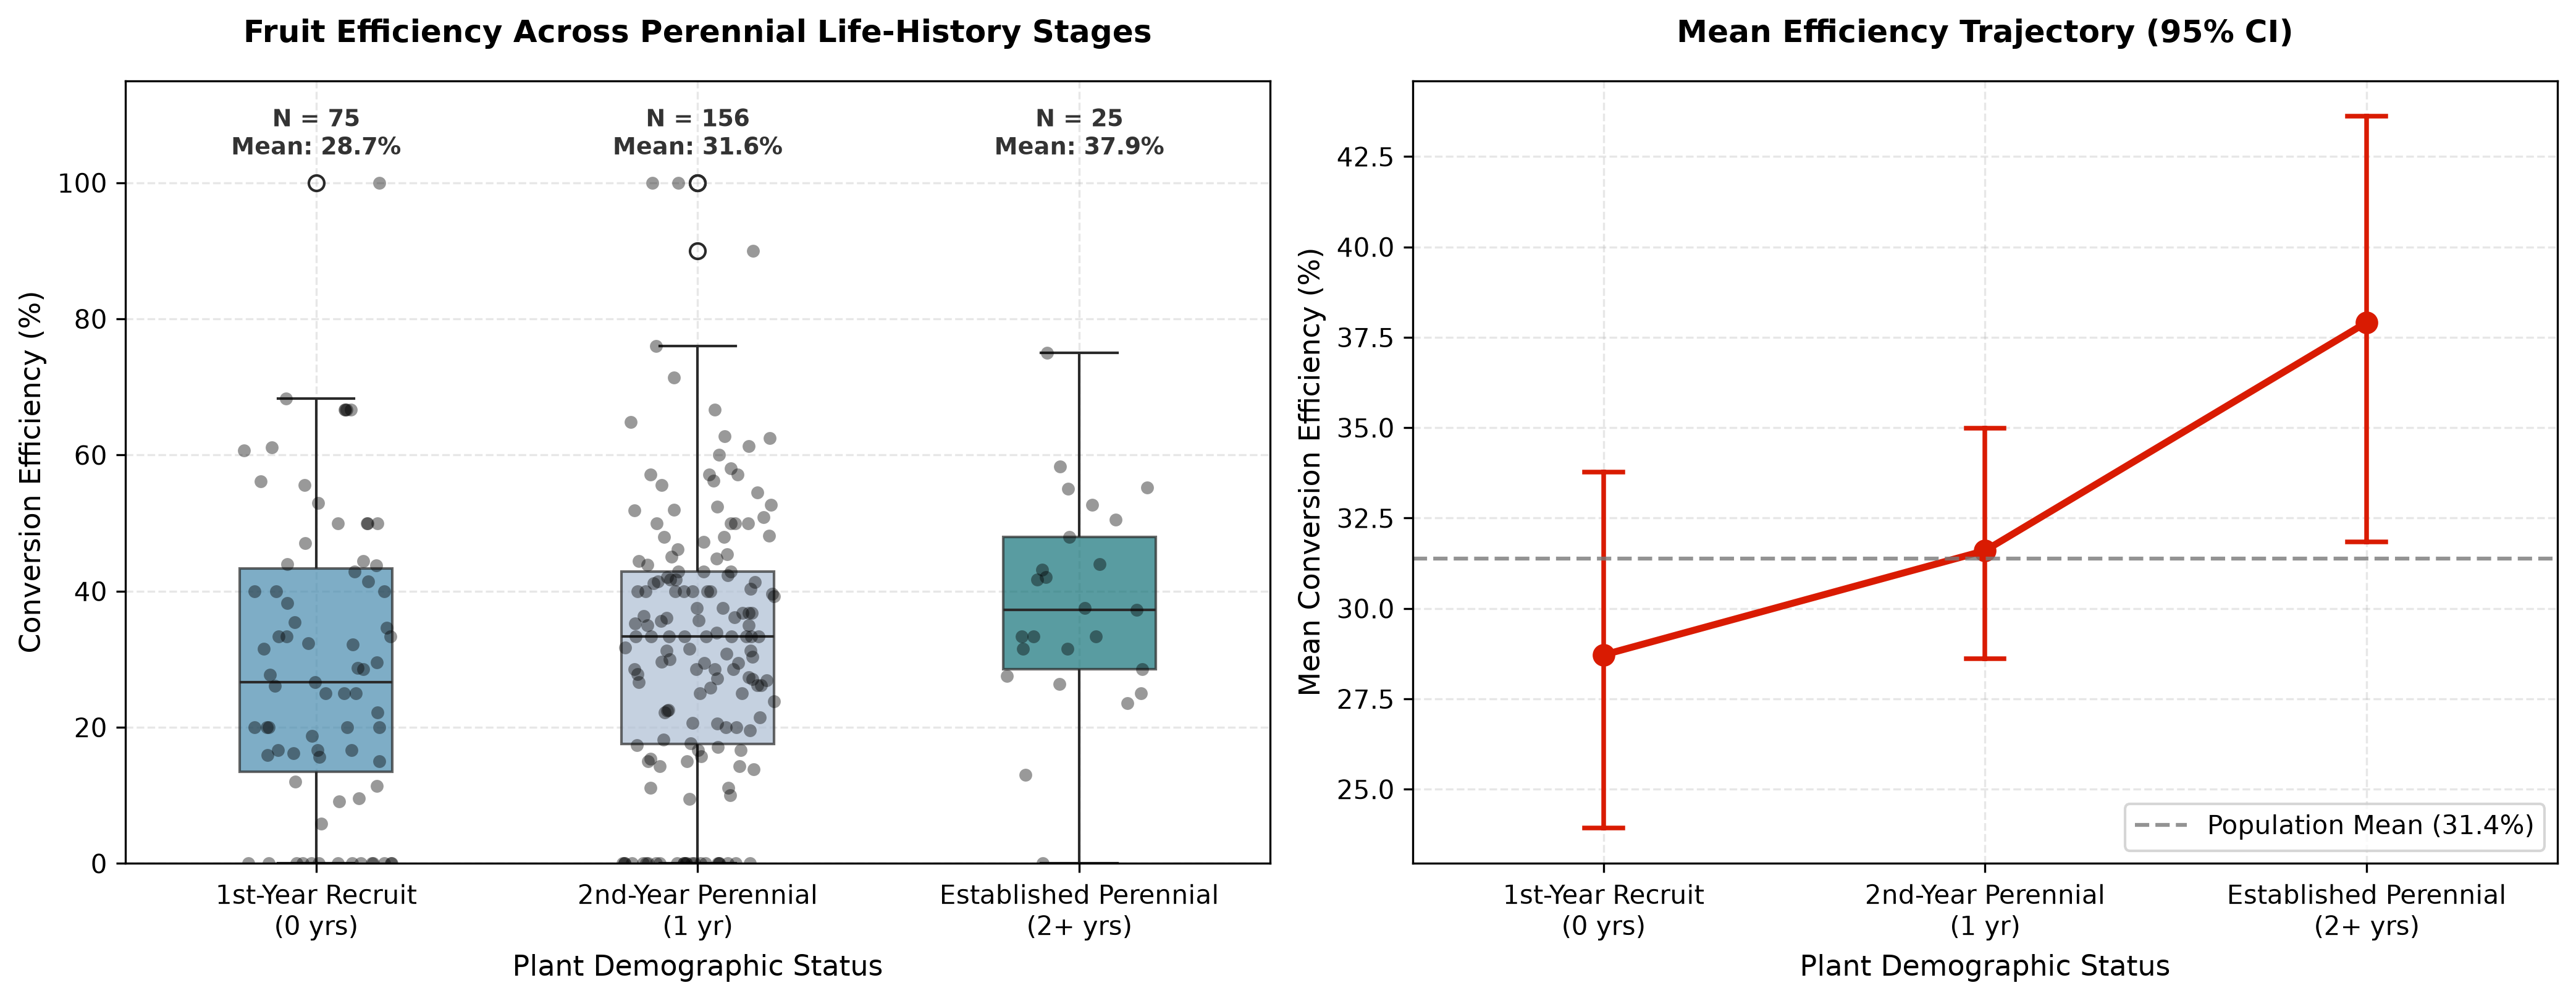

In [54]:
# I also make a boxplot to visualize the distribution of conversion efficiency across different perennial life-history stages.

# Filter out non-flowering plants
plot_df = plants_gdf[plants_gdf['Flower.colour'] != 'No flower'].copy()

# Ensure Success_Percentage exists
if 'Success_Percentage' not in plot_df.columns:
    total_flowers = plot_df['seed_max'] + plot_df['failures']
    plot_df['Success_Percentage'] = (plot_df['seed_max'] / total_flowers) * 100

# Map numerical Years_Alive_Count to clean biological labels
def label_status(years):
    if years == 0:
        return "1st-Year Recruit\n(0 yrs)"
    elif years == 1:
        return "2nd-Year Perennial\n(1 yr)"
    else:
        return "Established Perennial\n(2+ yrs)"
plot_df['Perennial_Status'] = plot_df['Years_Alive_Count'].apply(label_status)

# Calculate cohort statistics for plot annotations
cohort_stats = plot_df.groupby('Perennial_Status')['Success_Percentage'].agg(mean='mean',
median='median',
count='count'
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300) # set figure size and resolution
status_order = ["1st-Year Recruit\n(0 yrs)", "2nd-Year Perennial\n(1 yr)", "Established Perennial\n(2+ yrs)"]

# Boxplot showing median, IQR, and spread
sns.boxplot(
    data=plot_df,
    x='Perennial_Status',
    y='Success_Percentage',
    order=status_order,
    palette=['#a6bddb', '#3690c0', '#02818a'],
    hue='Perennial_Status',
    width=0.4,
    boxprops=dict(alpha=0.7),
    ax=ax1
)
# Stripplot overlay showing raw plant observations
sns.stripplot(
    data=plot_df,
    x='Perennial_Status',
    y='Success_Percentage',
    order=status_order,
    color='black',
    alpha=0.4,
    jitter=0.2,
    size=5,
    ax=ax1
)

# Annotate sample size (N) for each cohort
for i, status in enumerate(status_order):
    n_val = cohort_stats.loc[cohort_stats['Perennial_Status'] == status, 'count'].values[0]
    mean_val = cohort_stats.loc[cohort_stats['Perennial_Status'] == status, 'mean'].values[0]
    ax1.text(
        i, 103, f"N = {n_val}\nMean: {mean_val:.1f}%", 
        ha='center', va='bottom', fontsize=9, fontweight='bold', color='#333333'
    )

# Formatting
ax1.set_title("Fruit Efficiency Across Perennial Life-History Stages", fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel("Plant Demographic Status", fontsize=11)
ax1.set_ylabel("Conversion Efficiency (%)", fontsize=11)
ax1.set_ylim(0, 115)
ax1.grid(True, linestyle='--', alpha=0.3)
sns.pointplot(
    data=plot_df,
    x='Perennial_Status',
    y='Success_Percentage',
    order=status_order,
    color='#d91b02',
    capsize=0.1,
    err_kws={'linewidth': 1.8},
    markers='o',
    linestyles='-',
    ax=ax2
)
# Add population overall baseline reference line
overall_mean = plot_df['Success_Percentage'].mean()
ax2.axhline(overall_mean, color='#787878', linestyle='--', alpha=0.8, label=f'Population Mean ({overall_mean:.1f}%)')
ax2.set_title("Mean Efficiency Trajectory (95% CI)", fontsize=12, fontweight='bold', pad=15)
ax2.set_xlabel("Plant Demographic Status", fontsize=11)
ax2.set_ylabel("Mean Conversion Efficiency (%)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.3)
ax2.legend(loc='lower right', frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

In [55]:
# I look at the boundary counts (number of plants with 0% and 100% efficiency) to assess potential issues with the model assumptions.
zero_count = (plant_max["Success_Percentage"] == 0).sum()
hundred_count = (plant_max["Success_Percentage"] == 100).sum()
total_n = len(plant_max)
print(f"Boundary check: {zero_count} zeros ({zero_count/total_n:.1%}), {hundred_count} hundreds ({hundred_count/total_n:.1%})")
# Sample size vs. predictor ratio
print(f"Sample size (N): {total_n}")
# Target scaling to (0, 1) interval
y = plant_max["Success_Percentage"] / 100.0
# Apply Smithson & Verkuilen (2006) squeeze if exact 0 or 1 exist without inflated model
y_squeezed = (y * (total_n - 1) + 0.5) / total_n

Boundary check: 46 zeros (17.1%), 4 hundreds (1.5%)
Sample size (N): 269


## Plot the Spatial Distribution of efficiency

In [ ]:
# save as html file for interactive map visualization

# Identify ID columns
id_col_coords = (
    "PlantID" if "PlantID" in df_coordinates.columns else "PlantIDs"
)
id_col_df = "PlantID" if "PlantID" in df.columns else "PlantIDs"

# 2. Keep only valid plant IDs present in updated_file.csv
valid_plant_ids = df[id_col_df].dropna().unique()
df_coords_filtered = df_coordinates[
    df_coordinates[id_col_coords].isin(valid_plant_ids)
].copy()

# 3. Prefer .y coordinates, fallback to .x
df_coords_filtered["lat_clean"] = df_coords_filtered["Latitude.y"].combine_first(
    df_coords_filtered["Latitude.x"]
)
df_coords_filtered["lng_clean"] = df_coords_filtered[
    "Longitude.y"
].combine_first(df_coords_filtered["Longitude.x"])

# 4. Clean and aggregate per Plant ID
coords_clean = (
    df_coords_filtered.groupby(id_col_coords)[["lat_clean", "lng_clean"]]
    .mean()
    .reset_index()
    .dropna(subset=["lat_clean", "lng_clean"])
)

# 5. Calculate center coordinate
center_lat = coords_clean["lat_clean"].mean()
center_lng = coords_clean["lng_clean"].mean()

# 6. Initialize Folium Map with Esri Topo Tiles (Free, No API Key Required)
m = folium.Map(
    location=[center_lat, center_lng],
    zoom_start=15,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Topo Map",
)

# 7. Add HeatMap layer (No individual marker dots)
heat_data = coords_clean[["lat_clean", "lng_clean"]].values.tolist()
HeatMap(heat_data, radius=22, blur=15, min_opacity=0.35).add_to(m)

# 8. Save map to HTML file and embed in Jupyter Notebook
html_filename = "plant_distribution_map.html"
m.save(html_filename)

IFrame(src=html_filename, width="100%", height=500)

---
## Feature Evaluation

In [59]:
df_eval = plants_gdf.copy()

# Filter out non-blooming plants before splitting X and y
if "Flower.colour" in df_eval.columns:
    df_eval = df_eval[df_eval["Flower.colour"] != "No flower"].copy()

# Drop tri_ruggedness to resolve severe collinearity with slope_deg
if "tri_ruggedness" in df_eval.columns:
    df_eval.drop(columns=["tri_ruggedness"], inplace=True)

# Extract numeric UTM coordinates from geometry object
if "geometry" in df_eval.columns:
    df_eval["utm_easting"] = df_eval.geometry.x
    df_eval["utm_northing"] = df_eval.geometry.y
    df_eval.drop(columns=["geometry"], inplace=True)

# Target and predictor setup
target_col = "Success_Percentage"
cols_to_drop = ["PlantID", "lat", "lng", target_col]

X_raw = df_eval.drop(columns=[c for c in cols_to_drop if c in df_eval.columns])
y = df_eval[target_col]

# One-hot encode categorical features
# drop_first=True prevents the dummy variable trap (Hybrid is dropped as baseline reference)
X = pd.get_dummies(X_raw, columns=["Flower.colour"], drop_first=True, dtype=float)

summary_df = pd.DataFrame(
    {
        "Mean": X.mean(),
        "Std": X.std(),
        "Min": X.min(),
        "Median": X.median(),
        "Max": X.max(),
        "Skewness": X.skew(),
    }
).round(3)
print(f"Retained plants after removing 'No flower': {len(df_eval)}")
print("\n--- 1. Feature Univariate Summary & Skewness ---")
print(summary_df)

spearman_results = []
for col in X.columns:
    rho, pval = spearmanr(X[col], y)
    spearman_results.append({"Feature": col, "Spearman_rho": rho, "p_value": pval})
spearman_df = pd.DataFrame(spearman_results).sort_values(by="Spearman_rho", key=abs, ascending=False)
print("\n--- 2. Correlation with Target (Success_Percentage) ---")
print(spearman_df.to_string(index=False))

# Add intercept term for valid VIF baseline calculation
X_vif = sm.add_constant(X)
vif_data = []
for i in range(1, X_vif.shape[1]):  # Skip index 0 (the constant)
    col_name = X_vif.columns[i]
    vif_val = variance_inflation_factor(X_vif.values, i)
    vif_data.append({"Feature": col_name, "VIF": round(vif_val, 2)})
vif_df = pd.DataFrame(vif_data).sort_values(by="VIF", ascending=False)
print("\n--- 3. Variance Inflation Factor (VIF) ---")
print(vif_df.to_string(index=False))

Retained plants after removing 'No flower': 256

--- 1. Feature Univariate Summary & Skewness ---
                              Mean      Std          Min       Median  \
Years_Alive_Count            0.805    0.595        0.000        1.000   
dist_to_river_m             88.905   45.113       19.160       84.141   
elevation_m               1141.850    6.808     1125.107     1144.403   
slope_deg                   21.023   23.424        0.681        6.073   
northness                   -0.278    0.440       -1.000       -0.338   
ndvi                         0.214    0.076        0.000        0.204   
utm_easting             423853.308  324.781   423249.761   423727.602   
utm_northing           4686023.147   78.435  4685882.214  4686027.730   
Flower.colour_Magenta        0.363    0.482        0.000        0.000   
Flower.colour_Yellow         0.066    0.249        0.000        0.000   

                               Max  Skewness  
Years_Alive_Count            2.000     0.090  
dist

---

## Feature Evaluation Analysis
* slope_deg ($21.63$) and tri_ruggedness ($21.54$) are essentially measuring the exact same terrain steepness.
* elevation_m ($17.26$), utm_easting ($9.66$), and utm_northing ($7.46$) have elevated VIFs because elevation changes continuously along your geographical transect trajectory. (serious multicollinearity issue)
* lower.colour_No flower ($\rho = 0.173, p = 0.0097$): Statistically significant ($p < 0.01$). However, checking the univariate summary shows its mean is $0.027$ ($\sim 2.7\%$ of plants, or only $\sim 6$ individuals). Because the sample size is small, this signal should be interpreted as an observation of rare non-flowering status rather than a population driver.
* ndvi ($\rho = 0.131, p = 0.051$): Borderline statistically significant ($p \approx 0.05$). Higher canopy/vegetation vigor positively tracks plant performance.

How I will continue:    
Drop tri_ruggedness but retain slope_deg    
Drop utm_easting and northing        
Plot Spearman Correlation Matrix

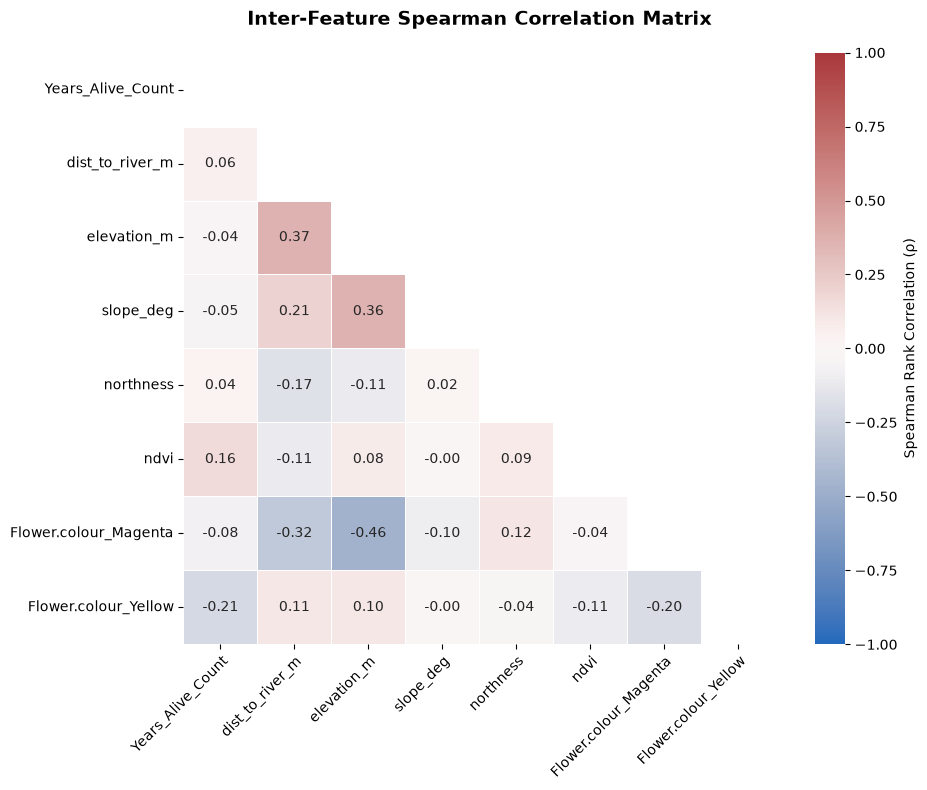

In [60]:
cols_to_drop = ["utm_easting", "utm_northing", "tri", "tri_ruggedness"]
# Drop specified columns
cols_to_drop_pattern = [
    col for col in X.columns
    if any(k in col.lower() for k in ["utm", "tri"])
]
X_clean = X.drop(columns=cols_to_drop_pattern, errors="ignore")
# Compute Spearman correlation
corr = X_clean.corr(method="spearman")
# Mask the upper triangle (including diagonal if desired)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",          # Red-Blue diverging palette
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman Rank Correlation (ρ)"}
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",              # Align the top-right corner of the label to the tick
    rotation_mode="anchor"   # Ensures rotation happens around the anchor point
)
# Ensure y-axis labels stay completely horizontal
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.title("Inter-Feature Spearman Correlation Matrix", fontsize=14, pad=20, fontweight="bold")
plt.tight_layout()
plt.show()

## Conclusion
I decided to drop TRI and UTM easting and northing

---

## Model decision

In [61]:
# Ensure target count variables exist in plants_gdf
plants_gdf["fruit_count"] = plant_max["Estim.Fruits.Nr"].astype(int)
plants_gdf["flower_count"] = plant_max["Estim.Flowers.Nr"].astype(int)
plants_gdf["failure_count"] = plant_max["Estim.Flowers.Nr"] - plant_max["Estim.Fruits.Nr"]
plants_gdf["y_prop"] = plants_gdf["Success_Percentage"] / 100.0

                                  
# --- Dummy Encoding for Flower Color ---
# Identify the color column name
color_col = "Flower.colour" if "Flower.colour" in plants_gdf.columns else "flower_color"

# Filter out plants with 'no color' or missing values
plants_gdf = plants_gdf[
    plants_gdf[color_col].notna() & 
    (~plants_gdf[color_col].astype(str).str.lower().isin(["no color", "none", "n/a", "nan"]))
].copy()

# Create dummy columns (Hybrid serves as the reference category where both dummies = 0)
plants_gdf["Flower.colour_Magenta"] = (plants_gdf[color_col].astype(str).str.lower() == "magenta").astype(int)
plants_gdf["Flower.colour_Yellow"] = (plants_gdf[color_col].astype(str).str.lower() == "yellow").astype(int)

# Predictor column list
predictor_cols = [
    "Years_Alive_Count",
    "dist_to_river_m",
    "elevation_m",
    "slope_deg",
    "northness",
    "ndvi",
    "Flower.colour_Magenta",
    "Flower.colour_Yellow"
]

# Filter predictors that are present in plants_gdf
predictor_cols = [col for col in predictor_cols if col in plants_gdf.columns]
formula_predictors = " + ".join(predictor_cols)

print(f"Data ready with N = {len(plants_gdf)} plants.")
print(f"Predictors ({len(predictor_cols)}): {predictor_cols}")

Data ready with N = 268 plants.
Predictors (8): ['Years_Alive_Count', 'dist_to_river_m', 'elevation_m', 'slope_deg', 'northness', 'ndvi', 'Flower.colour_Magenta', 'Flower.colour_Yellow']


In [65]:
flower_col = "flower_count" if "flower_count" in plants_gdf.columns else "Estim.Flowers.Nr"
fruit_col = "fruit_count" if "fruit_count" in plants_gdf.columns else "Estim.Fruits.Nr"

# Filter active fruit-bearing subset (1 <= Fruits <= Flowers)
df_filtered = plants_gdf[
    (plants_gdf[fruit_col] >= 1) & 
    (plants_gdf[fruit_col] <= plants_gdf[flower_col])
].copy()

# Compute log1p transforms
df_filtered['log_flowers'] = np.log1p(df_filtered[flower_col])
df_filtered['log_fruits'] = np.log1p(df_filtered[fruit_col])

# Master variable list across all 4 models
all_model_vars = [
    'log_fruits', 'log_flowers', 'Years_Alive_Count', 
    'Flower.colour_Magenta', 'Flower.colour_Yellow',
    'dist_to_river_m', 'elevation_m', 'slope_deg', 'northness', 'ndvi'
]

existing_vars = [v for v in all_model_vars if v in df_filtered.columns]

# Pre-filter NaNs across all predictors so Model 0, 1, 2, and 3 use identical rows (N=223)
df_filtered = df_filtered.dropna(subset=existing_vars).copy()

# STEP 2: DEFINE & FIT 4-STAGE HIERARCHICAL MODELS
# MODEL 0: Base Model (Floral Display Size Only) 
m0_formula = "log_fruits ~ log_flowers"
m0 = smf.ols(m0_formula, data=df_filtered).fit()

# MODEL 1: Base + Biological Traits
m1_formula = (
    "log_fruits ~ log_flowers + Q('Years_Alive_Count') + "
    "Q('Flower.colour_Magenta') + Q('Flower.colour_Yellow')"
)
m1 = smf.ols(m1_formula, data=df_filtered).fit()

# MODEL 2: Base + Microclimate & Topography 
m2_formula = (
    "log_fruits ~ log_flowers + Q('dist_to_river_m') + "
    "Q('elevation_m') + Q('slope_deg') + Q('northness') + Q('ndvi')"
)
m2 = smf.ols(m2_formula, data=df_filtered).fit()

# MODEL 3: Full Combined Model (Base + Biological + Microclimate) 
m3_formula = (
    "log_fruits ~ log_flowers + Q('Years_Alive_Count') + "
    "Q('Flower.colour_Magenta') + Q('Flower.colour_Yellow') + "
    "Q('dist_to_river_m') + Q('elevation_m') + Q('slope_deg') + "
    "Q('northness') + Q('ndvi')"
)
m3 = smf.ols(m3_formula, data=df_filtered).fit()


# STEP 3: STATISTICAL METRICS & SEQUENTIAL BLOCK ANOVA
models = [
    ("Model 0 (Base: Floral Display)", m0),
    ("Model 1 (+ Biological Traits)", m1),
    ("Model 2 (+ Microclimate & Topography)", m2),
    ("Model 3 (Full Combined Model)", m3)
]

print(f"Hierarchical execution complete with N = {len(df_filtered)} plants.\n")
print("=== HIERARCHICAL MODEL COMPARISON ===")
for name, mod in models:
    print(f"\n{name}:")
    print(f"  * R-squared:          {mod.rsquared:.4f}")
    print(f"  * Adjusted R-squared: {mod.rsquared_adj:.4f}")
    print(f"  * AIC:                {mod.aic:.2f}")
    print(f"  * BIC:                {mod.bic:.2f}")

# Sequential ANOVA tests comparing nested blocks
print("\n=== NESTED BLOCK ANOVA: Biological Addition (Model 0 -> Model 1) ===")
print(sm.stats.anova_lm(m0, m1))

print("\n=== NESTED BLOCK ANOVA: Microclimate Addition (Model 0 -> Model 2) ===")
print(sm.stats.anova_lm(m0, m2))

print("\n=== NESTED BLOCK ANOVA: Full System Incremental (Model 0 -> Model 1 -> Model 3) ===")
print(sm.stats.anova_lm(m0, m1, m3))

Hierarchical execution complete with N = 223 plants.

=== HIERARCHICAL MODEL COMPARISON ===

Model 0 (Base: Floral Display):
  * R-squared:          0.8034
  * Adjusted R-squared: 0.8025
  * AIC:                236.82
  * BIC:                243.63

Model 1 (+ Biological Traits):
  * R-squared:          0.8063
  * Adjusted R-squared: 0.8028
  * AIC:                239.46
  * BIC:                256.49

Model 2 (+ Microclimate & Topography):
  * R-squared:          0.8091
  * Adjusted R-squared: 0.8038
  * AIC:                240.26
  * BIC:                264.11

Model 3 (Full Combined Model):
  * R-squared:          0.8115
  * Adjusted R-squared: 0.8036
  * AIC:                243.41
  * BIC:                277.48

=== NESTED BLOCK ANOVA: Biological Addition (Model 0 -> Model 1) ===
   df_resid        ssr  df_diff   ss_diff         F    Pr(>F)
0     221.0  37.088913      0.0       NaN       NaN       NaN
1     218.0  36.534430      3.0  0.554483  1.102863  0.348864

=== NESTED BLOCK A

# FAIR Principles

This project aligns with FAIR principles by balancing open computational workflows with responsible data governance. Hosting the repository on GitHub ensures accessibility, allowing peer researchers to inspect and evaluate the analytical framework. Abiotic features and coordinate data were processed through clear, open spatial pipelines using standard geospatial libraries like GeoPandas and Rasterio, making data extraction and spatial join logic transparent and easily reproducible. 

To respect data ownership, the repository uses a dual-access governance model: the software, processing workflows, and Jupyter Notebooks are openly licensed under a permissive MIT License for maximum reusability, while the raw biological datasets from The Nick Barton Group at ISTA remain restricted under a proprietary license to protect non-public field data.

Reusability is established through a modern Python 3.13 environment managed via uv and defined in pyproject.toml, where dependencies are pinned using compatible semantic versioning to prevent breaking API changes while allowing necessary patch updates. 


The project could have achieved higher baseline reproducibility if I had chosen a pre-cleaned, open-access benchmark dataset better suited for the purpose. Instead, I worked with a messy, non-public, field-collected dataset. Although I have strived to make the workflow as transparent and reproducible as possible given these data constraints, there remains valuable room for future refinement in data standardization and pipeline set up.